# SHAP / Explainable AI for Final Dementia Classifier
standalone explainability notebook for the final saved multiclass dementia classifier bundle.

It does four things:

1. Loads the saved model bundle (dementia_classifier_bundle.joblib)
2. Rebuilds the exact train/test feature matrices from the cohort file
3. Computes SHAP explanations for the final logistic regression model
4. Exports:
   - global SHAP plots
   - per-class feature importance tables
   - local explanation plots
   - vascular threshold margin table



## 0) Configuration


Expected project layout:
- ../output/cohort_E8b_vascular_signal_H5.csv
- ../output/dementia_classifier_bundle.joblib


In [2]:

import os
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")


EXP_NAME = "E8b_vascular_signal"
H = 5
RANDOM_STATE = 42

OUTPUT_DIR = Path("..") / "output"
BUNDLE_PATH = OUTPUT_DIR / "dementia_classifier_bundle.joblib"
COHORT_PATH = OUTPUT_DIR / f"cohort_{EXP_NAME}_H{H}.csv"

SHAP_OUT_DIR = OUTPUT_DIR / "shap_outputs"
FIG_DIR = SHAP_OUT_DIR / "figures"
TABLE_DIR = SHAP_OUT_DIR / "tables"

SHAP_OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

print("Bundle path:", BUNDLE_PATH)
print("Cohort path:", COHORT_PATH)
print("Output dir :", SHAP_OUT_DIR)

if not BUNDLE_PATH.exists():
    raise FileNotFoundError(f"Could not find saved model bundle: {BUNDLE_PATH}")

if not COHORT_PATH.exists():
    raise FileNotFoundError(f"Could not find cohort file: {COHORT_PATH}")


Bundle path: ../output/dementia_classifier_bundle.joblib
Cohort path: ../output/cohort_E8b_vascular_signal_H5.csv
Output dir : ../output/shap_outputs


## 1) Loading saved model bundle

In [3]:

bundle = joblib.load(BUNDLE_PATH)

clf_best = bundle["model"]
best_T = bundle["threshold"]
class_order = np.array(bundle["class_order"])
feature_cols = list(bundle["feature_cols"])

print("Loaded classes:", class_order.tolist())
print("Vascular threshold:", best_T)
print("Number of original feature columns:", len(feature_cols))

preprocess = clf_best.named_steps["preprocess"]
lr_model = clf_best.named_steps["model"]

print("\nPipeline steps:", clf_best.named_steps.keys())
print("Underlying model:", type(lr_model).__name__)


Loaded classes: ['AD', 'NoDementia_Hy', 'PD_LBD', 'Vascular']
Vascular threshold: 0.36
Number of original feature columns: 67

Pipeline steps: dict_keys(['preprocess', 'model'])
Underlying model: LogisticRegression


In [4]:

df = pd.read_csv(COHORT_PATH)
print("Loaded cohort:", df.shape)
display(df.head(3))
print(df["label"].value_counts(dropna=False))


Loaded cohort: (38341, 74)


,NACCID,baseline_date,label,max_follow_years,has_H_followup,has_dementia_H,NACCAGE,SEX,RACE,HISPANIC,...,FOCLSIGN,HACHIN,HACHIN_GE_4,HACHIN_GE_7,STROKE_TIA_ANY,VASC_MED_COUNT,GAIT_ANY,NACCMOM,NACCDAD,SIVDFIND
0,NACC000011,2006-04-17,Censored,3.296372,False,False,62.0,2.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0,0.0,0,NaN,NaN,NaN
1,NACC000034,2015-07-16,NoDementia_Hy,6.986995,True,False,79.0,2.0,1.0,0.0,...,NaN,NaN,NaN,NaN,0,2.0,0,1.0,1.0,0.0
2,NACC000067,2012-05-23,Censored,2.088980,False,False,60.0,1.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0,1.0,1,1.0,0.0,NaN


label
Censored         23300
NoDementia_Hy    11083
AD                3013
MixedOrOther       504
PD_LBD             289
Vascular           152
Name: count, dtype: int64


In [5]:

def fix_categorical_codes(X: pd.DataFrame) -> pd.DataFrame:
    X = X.copy()
    CAT_CODE_VARS = [c for c in ["SEX", "RACE", "HISPANIC", "NACCUDSD"] if c in X.columns]
    STD_MISS = {-4, 9}

    for c in CAT_CODE_VARS:
        s = pd.to_numeric(X[c], errors="coerce")
        s = s.mask(s.isin(list(STD_MISS)), np.nan)
        X[c] = s

    if "RACE" in X.columns:
        X["RACE"] = X["RACE"].mask(X["RACE"].isin([99]), np.nan)

    for c in CAT_CODE_VARS:
        s = pd.to_numeric(X[c], errors="coerce")
        X[c] = s.map(lambda v: np.nan if pd.isna(v) else str(int(v))).astype(object)

    if "EDUC" in X.columns:
        educ_num = pd.to_numeric(X["EDUC"], errors="coerce")
        _ = educ_num 

    X = X.replace({pd.NA: np.nan})
    for c in X.columns:
        if X[c].dtype == "bool":
            X[c] = X[c].astype(int)

    return X


def prepare_experiment_df(df_in: pd.DataFrame, exp_name: str):
    df_in = df_in.copy()

    KEEP = {"AD", "NoDementia_Hy", "PD_LBD", "Vascular"}
    df4 = df_in[df_in["label"].isin(KEEP)].copy()

    drop_cols = [
        c for c in [
            "NACCID", "baseline_date", "label", "has_H_followup",
            "has_dementia_H", "max_follow_years", "abs_days_from_baseline",
            "NACCUDSD"
        ]
        if c in df4.columns
    ]

    if exp_name == "E8_clean_vascular":
        raw_vasc = [
            "DIABETES","HYPERTEN","HYPERCHO","CVAFIB","CBSTROKE",
            "CBTIA","CVCHF","CVANGINA","CVBYPASS","CVHVALVE"
        ]
        drop_cols += [c for c in raw_vasc if c in df4.columns]

        raw_meds = [
            "NACCLIPL","NACCAC","NACCBETA","NACCCCBS",
            "NACCDIUR","NACCANGI","NACCVASD"
        ]
        drop_cols += [c for c in raw_meds if c in df4.columns]

    if exp_name == "E9_clean_exec_ratio":
        drop_cols += [c for c in ["TRAILA","TRAILB","TRAILA_missing","TRAILB_missing"] if c in df4.columns]

    X = df4.drop(columns=[c for c in drop_cols if c in df4.columns]).copy()
    y = df4["label"].astype(str).copy()

    return df4, X, y


df4, X, y = prepare_experiment_df(df, EXP_NAME)
X = fix_categorical_codes(X)

missing_in_current = [c for c in feature_cols if c not in X.columns]
extra_in_current = [c for c in X.columns if c not in feature_cols]

if missing_in_current:
    raise ValueError(f"These saved feature columns are missing from current cohort file: {missing_in_current[:20]}")

if extra_in_current:
    print("Warning: extra columns exist in the rebuilt cohort and will be dropped.")
    print(extra_in_current[:20])

X = X[feature_cols].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print("df4 shape   :", df4.shape)
print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)
print("\nTrain label counts:")
print(y_train.value_counts())
print("\nTest label counts:")
print(y_test.value_counts())


df4 shape   : (14537, 74)
X_train shape: (11629, 67)
X_test shape : (2908, 67)

Train label counts:
label
NoDementia_Hy    8866
AD               2410
PD_LBD            231
Vascular          122
Name: count, dtype: int64

Test label counts:
label
NoDementia_Hy    2217
AD                603
PD_LBD             58
Vascular           30
Name: count, dtype: int64


## 3) Transforming data using the saved preprocessing pipeline

In [6]:

X_train_pre = preprocess.transform(X_train)
X_test_pre = preprocess.transform(X_test)

feature_names_pre = preprocess.get_feature_names_out()

print("Transformed train shape:", X_train_pre.shape)
print("Transformed test shape :", X_test_pre.shape)
print("Number of transformed features:", len(feature_names_pre))

feature_names_pre[:20]


Transformed train shape: (11629, 74)
Transformed test shape : (2908, 74)
Number of transformed features: 74


array(['num__NACCAGE', 'num__EDUC', 'num__NACCMMSE', 'num__NACCMOCA',
       'num__TRAILA', 'num__TRAILB', 'num__ANIMALS', 'num__BOSTON',
       'num__CDRSUM', 'num__CDRGLOB', 'num__NACCMMSE_missing',
       'num__NACCMOCA_missing', 'num__TRAILA_missing',
       'num__TRAILB_missing', 'num__CDRSUM_missing', 'num__COGFLUC',
       'num__BEVHALL', 'num__BEREM', 'num__PARKSIGN', 'num__BRADY'],
      dtype=object)

In [7]:

def predict_with_vascular_threshold(proba: np.ndarray, class_order, best_T: float):
    class_order = np.array(class_order)
    vas_idx = list(class_order).index("Vascular")
    preds = []
    for p in proba:
        if p[vas_idx] >= best_T:
            preds.append("Vascular")
        else:
            preds.append(class_order[np.argmax(p)])
    return np.array(preds)


def collapse_feature_name(name: str) -> str:
    if name.startswith("num__"):
        return name.replace("num__", "")
    if name.startswith("cat__"):
        name = name.replace("cat__", "")
        if "_" in name:
            return name.rsplit("_", 1)[0]
        return name
    return name


def row_to_dense(row):
    if hasattr(row, "toarray"):
        return row.toarray().ravel()
    return np.asarray(row).ravel()


def save_current_fig(filename: str):
    out = FIG_DIR / filename
    plt.tight_layout()
    plt.savefig(out, dpi=200, bbox_inches="tight")
    plt.show()
    print("Saved:", out)


In [8]:
import re
# Human-readable feature labels

FEATURE_LABELS = {
    # Core severity / cognition
    "CDRGLOB": "CDRGLOB (CDR Global Score)",
    "CDRSUM": "CDRSUM (CDR Sum of Boxes)",
    "NACCMOCA": "NACCMOCA (MoCA Score)",
    "NACCMMSE": "NACCMMSE (MMSE Score)",
    "NACCGDS": "NACCGDS (Geriatric Depression Scale)",
    "NACCAGE": "NACCAGE (Age)",
    "EDUC": "EDUC (Years of Education)",

    # Neuropsych tests
    "TRAILA": "TRAILA (Trail Making Test A)",
    "TRAILB": "TRAILB (Trail Making Test B)",
    "DIGBACCT": "DIGBACCT (Digit Span Backward Total)",
    "DIGBACLS": "DIGBACLS (Digit Span Backward Longest Span)",
    "ANIMALS": "ANIMALS (Animal Fluency)",
    "BOSTON": "BOSTON (Boston Naming Test)",

    # Depression / behavior / function
    "DEP2YRS": "DEP2YRS (Depression in Last 2 Years)",
    "BEVHALL": "BEVHALL (Visual Hallucinations)",
    "BEREM": "BEREM (REM Sleep Behavior Symptoms)",
    "COGFLUC": "COGFLUC (Cognitive Fluctuations)",
    "POSTINST": "POSTINST (Postural Instability)",

    # Vascular / medical
    "HYPERTEN": "HYPERTEN (Hypertension)",
    "DIABETES": "DIABETES (Diabetes)",
    "HACHIN": "HACHIN (Hachinski Ischemic Score)",
    "CVD": "CVD (Vascular Brain Injury Etiology)",
    "CBTIA": "CBTIA (TIA History)",
    "CBSTROKE": "CBSTROKE (Stroke History)",
    "STROKE_TIA_ANY": "STROKE_TIA_ANY (Any Stroke/TIA History)",
    "CVAFIB": "CVAFIB (Atrial Fibrillation)",
    "CVANGIO": "CVANGIO (Cardiac Angioplasty)",
    "CVOTHR": "CVOTHR (Other Cardiovascular Condition)",
    "CVDCOG": "CVDCOG (Cognitive Impact of Vascular Disease)",

    # Parkinsonism / motor
    "BRADY": "BRADY (Bradykinesia)",
    "RIGIDL": "RIGIDL (Left Rigidity)",
    "RIGIDR": "RIGIDR (Right Rigidity)",
    "RESTTRL": "RESTTRL (Left Rest Tremor)",
    "RESTTRR": "RESTTRR (Right Rest Tremor)",
    "SLOWINGL": "SLOWINGL (Left Motor Slowing)",
    "SLOWINGR": "SLOWINGR (Right Motor Slowing)",
    "PARKGAIT": "PARKGAIT (Parkinsonian Gait)",
    "PARKSIGN": "PARKSIGN (Parkinsonian Signs)",
    "GAITDIS": "GAITDIS (Gait Disorder)",
    "GAIT_ANY": "GAIT_ANY (Any Gait Disorder)",

    # Demographics / family history
    "SEX": "SEX (Biological Sex)",
    "RACE": "RACE (Race)",
    "HISPANIC": "HISPANIC (Hispanic Ethnicity)",
    "NACCMOM": "NACCMOM (Maternal Dementia History)",
    "NACCDAD": "NACCDAD (Paternal Dementia History)",
}

PLOT_FEATURE_LABELS = {
    "CDRGLOB": "CDRGLOB (CDR Global)",
    "CDRSUM": "CDRSUM (CDR Sum Boxes)",
    "NACCMOCA": "NACCMOCA (MoCA)",
    "NACCMMSE": "NACCMMSE (MMSE)",
    "NACCGDS": "NACCGDS (GDS)",
    "NACCAGE": "NACCAGE (Age)",
    "EDUC": "EDUC (Education)",
    "TRAILA": "TRAILA (Trail A)",
    "TRAILB": "TRAILB (Trail B)",
    "DIGBACCT": "DIGBACCT (Digit Backward Total)",
    "DIGBACLS": "DIGBACLS (Digit Backward Span)",
    "ANIMALS": "ANIMALS (Animal Fluency)",
    "BOSTON": "BOSTON (Boston Naming)",
    "DEP2YRS": "DEP2YRS (Recent Depression)",
    "BEVHALL": "BEVHALL (Hallucinations)",
    "BEREM": "BEREM (REM Behavior)",
    "COGFLUC": "COGFLUC (Cog Fluctuations)",
    "POSTINST": "POSTINST (Postural Instability)",
    "HYPERTEN": "HYPERTEN (Hypertension)",
    "DIABETES": "DIABETES (Diabetes)",
    "HACHIN": "HACHIN (Hachinski)",
    "CVD": "CVD (Vascular Injury)",
    "CBTIA": "CBTIA (TIA)",
    "CBSTROKE": "CBSTROKE (Stroke)",
    "STROKE_TIA_ANY": "STROKE/TIA History",
    "CVAFIB": "CVAFIB (A-fib)",
    "CVANGIO": "CVANGIO (Angioplasty)",
    "CVOTHR": "CVOTHR (Other CV)",
    "CVDCOG": "CVDCOG (Vascular Cog Impact)",
    "BRADY": "BRADY (Bradykinesia)",
    "RIGIDL": "RIGIDL (Left Rigidity)",
    "RIGIDR": "RIGIDR (Right Rigidity)",
    "RESTTRL": "RESTTRL (Left Rest Tremor)",
    "RESTTRR": "RESTTRR (Right Rest Tremor)",
    "SLOWINGL": "SLOWINGL (Left Slowing)",
    "SLOWINGR": "SLOWINGR (Right Slowing)",
    "PARKGAIT": "PARKGAIT (Parkinsonian Gait)",
    "PARKSIGN": "PARKSIGN (Parkinsonian Signs)",
    "GAITDIS": "GAITDIS (Gait Disorder)",
    "GAIT_ANY": "GAIT_ANY (Any Gait Disorder)",
    "SEX": "SEX",
    "RACE": "RACE",
    "HISPANIC": "HISPANIC",
    "NACCMOM": "NACCMOM (Maternal Dementia Hx)",
    "NACCDAD": "NACCDAD (Paternal Dementia Hx)",
}

def plot_feature_name(name: str) -> str:
    raw = strip_transform_prefix(name)

    m = re.match(r"^([A-Z0-9]+)_(.+)$", raw)
    if m and m.group(1) in PLOT_FEATURE_LABELS:
        base = m.group(1)
        level = m.group(2)
        return f"{PLOT_FEATURE_LABELS[base]} = {level}"

    return PLOT_FEATURE_LABELS.get(raw, raw)

def strip_transform_prefix(name: str) -> str:
    name = str(name)
    for prefix in ["num__", "cat__"]:
        if name.startswith(prefix):
            return name[len(prefix):]
    return name

def readable_feature_name(name: str) -> str:
    """
    Convert transformed or collapsed feature name into a readable label.
    Examples:
      num__CDRGLOB -> CDRGLOB (CDR Global Score)
      cat__SEX_1   -> SEX (Biological Sex) = level 1
      CDRSUM       -> CDRSUM (CDR Sum of Boxes)
    """
    raw = strip_transform_prefix(name)

    # one-hot categories
    m = re.match(r"^([A-Z0-9]+)_(.+)$", raw)
    if m and m.group(1) in FEATURE_LABELS:
        base = m.group(1)
        level = m.group(2)
        return f"{FEATURE_LABELS[base]} = {level}"

    # plain feature
    return FEATURE_LABELS.get(raw, raw)

## 4) Building SHAP explainer

In [9]:

rng = np.random.default_rng(42)
bg_size = min(300, X_train_pre.shape[0])
bg_idx = rng.choice(X_train_pre.shape[0], size=bg_size, replace=False)
X_background = X_train_pre[bg_idx]

sample_size = min(300, X_test_pre.shape[0])
X_explain = X_test_pre[:sample_size]

explainer = shap.LinearExplainer(
    lr_model,
    X_background,
    feature_names=feature_names_pre
)

shap_exp = explainer(X_explain)

print("Type:", type(shap_exp))
print("SHAP values shape:", np.shape(shap_exp.values))
print("Base values shape:", np.shape(shap_exp.base_values))
print("Explain subset size:", sample_size)


Type: <class 'shap._explanation.Explanation'>
SHAP values shape: (300, 74, 4)
Base values shape: (300, 4)
Explain subset size: 300


## 5) Global SHAP summary plots for each class

In [10]:

# for k, cls in enumerate(class_order):
#     print(f"\n===== Global SHAP summary: {cls} =====")
#     plt.figure()
#     shap.summary_plot(
#         shap_exp.values[:, :, k],
#         X_explain,
#         feature_names=feature_names_pre,
#         show=False
#     )
#     plt.title(f"SHAP summary for class: {cls}")
#     save_current_fig(f"summary_{cls}.png")


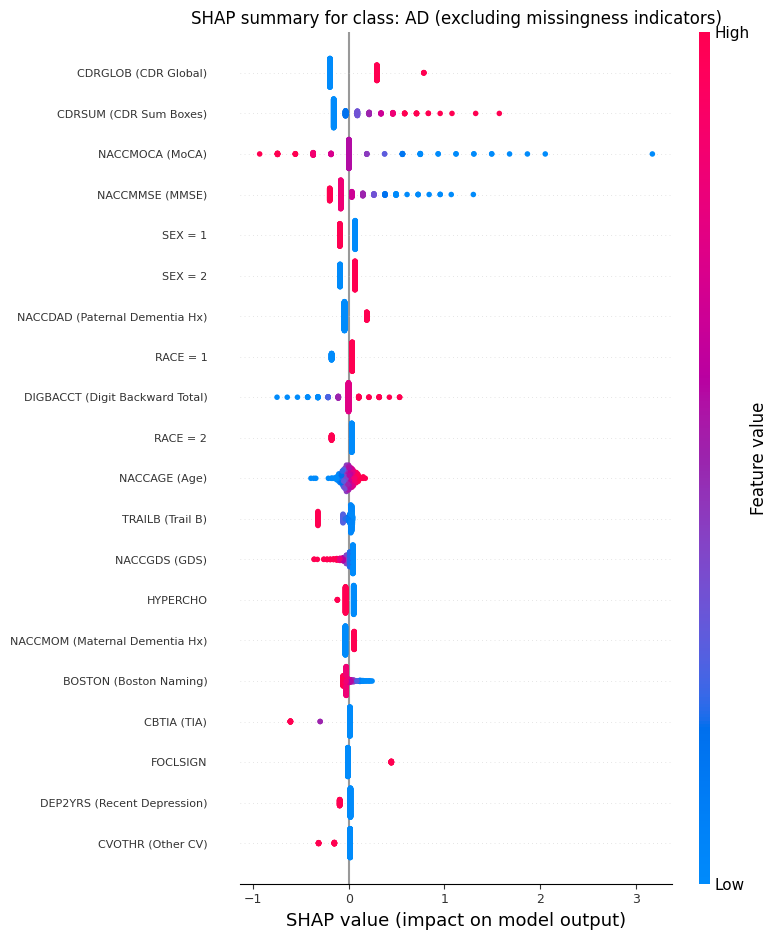

Saved: ../output/shap_outputs/figures/summary_AD_clean.png


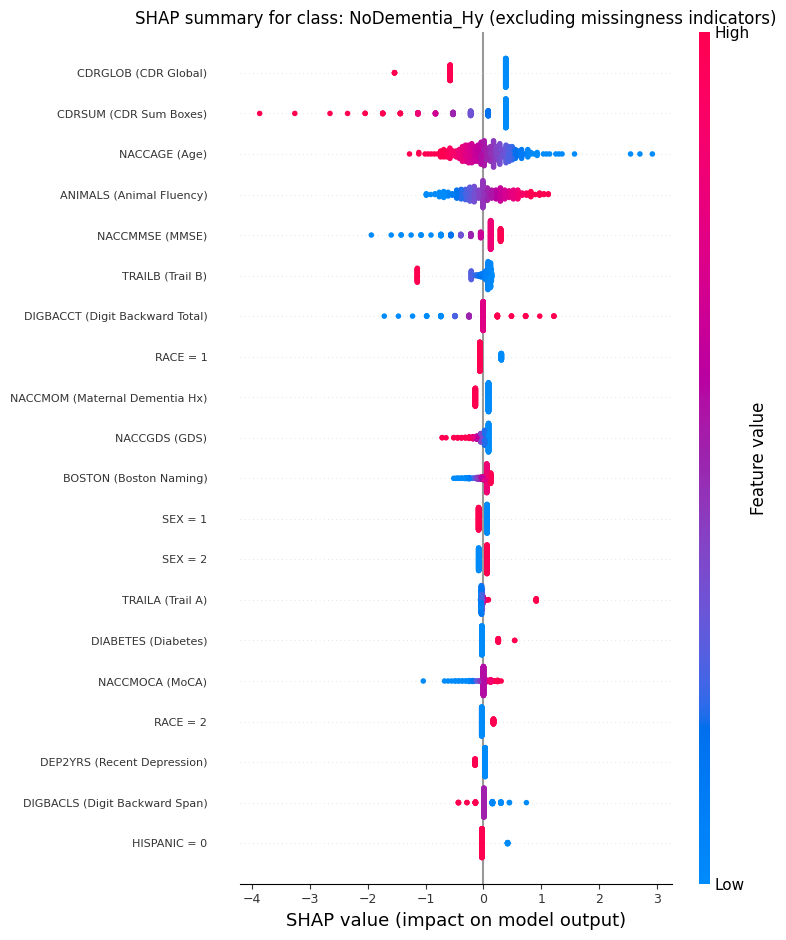

Saved: ../output/shap_outputs/figures/summary_NoDementia_Hy_clean.png


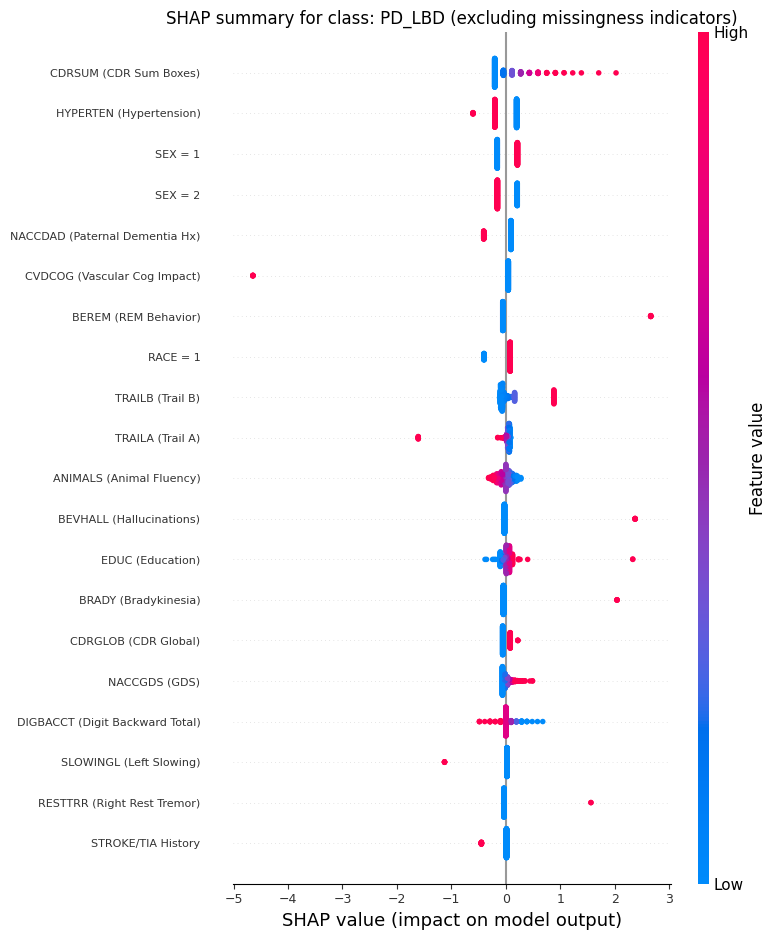

Saved: ../output/shap_outputs/figures/summary_PD_LBD_clean.png


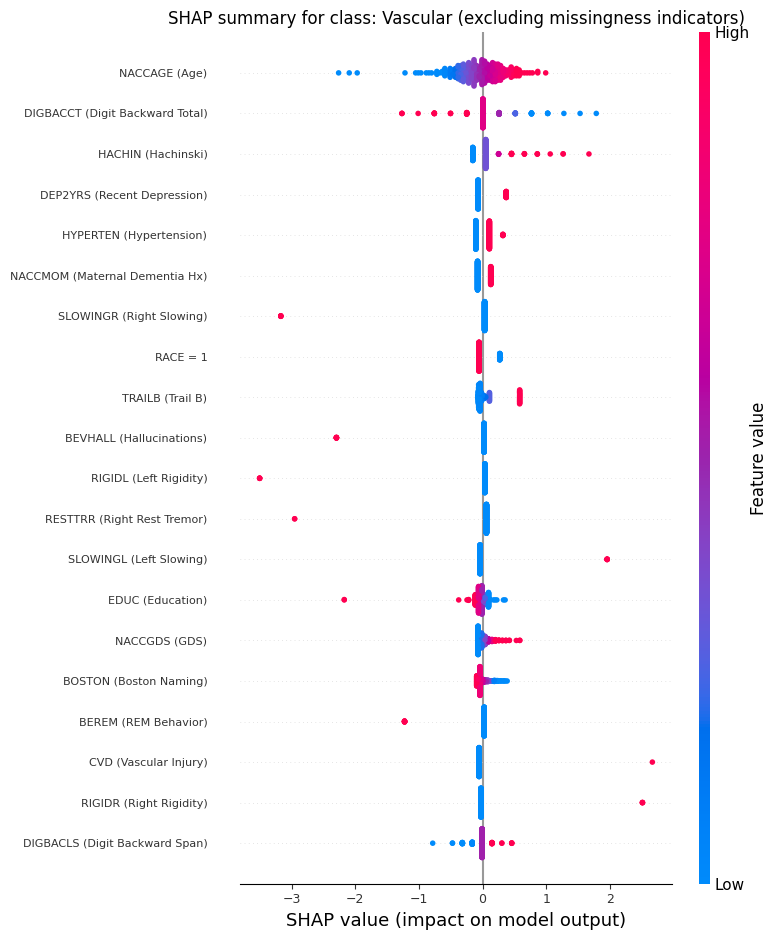

Saved: ../output/shap_outputs/figures/summary_Vascular_clean.png


In [11]:
# Clean beeswarm plots: exclude transformed missingness indicators and use human-readable feature labels

feature_names_pre_list = list(feature_names_pre)

clean_feature_idx = [
    j for j, f in enumerate(feature_names_pre_list)
    if not str(f).upper().endswith("_MISSING")
]

X_explain_clean = X_explain[:, clean_feature_idx]
feature_names_pre_clean = [feature_names_pre_list[j] for j in clean_feature_idx]
feature_names_pre_clean_readable = [plot_feature_name(f) for f in feature_names_pre_clean]

for k, cls in enumerate(class_order):

    plt.figure(figsize=(10, 8))

    shap.summary_plot(
        shap_exp.values[:, clean_feature_idx, k],
        X_explain_clean,
        feature_names=feature_names_pre_clean_readable,
        show=False
    )

    ax = plt.gca()

    ax.tick_params(axis='y', labelsize=8)
    ax.tick_params(axis='x', labelsize=9)

    plt.gcf().subplots_adjust(left=0.40)

    plt.title(
        f"SHAP summary for class: {cls} (excluding missingness indicators)",
        fontsize=12
    )

    save_current_fig(f"summary_{cls}_clean.png")

    plt.show()
    plt.close()

## 6) Global feature-importance tables

In [12]:

global_rows = []

for k, cls in enumerate(class_order):
    mean_abs_shap = np.abs(shap_exp.values[:, :, k]).mean(axis=0)
    tmp = pd.DataFrame({
        "feature": feature_names_pre,
        "mean_abs_shap": mean_abs_shap,
        "class": cls
    }).sort_values("mean_abs_shap", ascending=False)
    global_rows.append(tmp)

global_shap_df = pd.concat(global_rows, ignore_index=True)
global_csv = TABLE_DIR / "global_shap_importance_by_class.csv"
global_shap_df.to_csv(global_csv, index=False)

print("Saved:", global_csv)
display(global_shap_df.groupby("class", group_keys=False).head(15))


Saved: ../output/shap_outputs/tables/global_shap_importance_by_class.csv


,feature,mean_abs_shap,class
0,num__CDRGLOB,0.237853,AD
1,num__CDRSUM,0.188561,AD
2,num__NACCMMSE_missing,0.183969,AD
3,num__NACCMOCA,0.167212,AD
4,num__NACCMMSE,0.157442,AD
5,cat__SEX_1,0.078494,AD
6,cat__SEX_2,0.076481,AD
7,num__NACCDAD,0.075495,AD
8,cat__RACE_1,0.062765,AD
9,num__DIGBACCT,0.054727,AD


In [13]:
# Displaying filters for cleaner SHAP presentation
# Keeping these variables in the model, but hiding them for display plots/tables

def is_missing_feature_name(feat: str) -> bool:
    feat_u = str(feat).upper()
    return feat_u.endswith("_MISSING") or feat_u.startswith("MISSING_")

def is_display_feature_basic(feat: str) -> bool:
    return not is_missing_feature_name(feat)


collapsed_rows = []

for k, cls in enumerate(class_order):
    mean_abs_shap = np.abs(shap_exp.values[:, :, k]).mean(axis=0)
    tmp = pd.DataFrame({
        "feature_raw": feature_names_pre,
        "feature_base": [collapse_feature_name(f) for f in feature_names_pre],
        "mean_abs_shap": mean_abs_shap,
        "class": cls
    })
    tmp = (
        tmp.groupby(["class", "feature_base"], as_index=False)["mean_abs_shap"]
        .sum()
        .sort_values(["class", "mean_abs_shap"], ascending=[True, False])
    )
    collapsed_rows.append(tmp)

collapsed_global_shap_df = pd.concat(collapsed_rows, ignore_index=True)
collapsed_csv = TABLE_DIR / "global_shap_importance_collapsed.csv"
collapsed_global_shap_df.to_csv(collapsed_csv, index=False)

collapsed_global_shap_display_df = collapsed_global_shap_df[
    collapsed_global_shap_df["feature_base"].apply(is_display_feature_basic)
].copy()

collapsed_global_shap_display_df.to_csv(
    os.path.join(OUTPUT_DIR, "global_shap_importance_collapsed_display.csv"),
    index=False
)

print("Saved:", collapsed_csv)
display(collapsed_global_shap_display_df.groupby("class", group_keys=False).head(15))


Saved: ../output/shap_outputs/tables/global_shap_importance_collapsed.csv


,class,feature_base,mean_abs_shap
0,AD,CDRGLOB,0.237853
1,AD,CDRSUM,0.188561
3,AD,NACCMOCA,0.167212
4,AD,NACCMMSE,0.157442
5,AD,SEX,0.154975
6,AD,RACE,0.124845
7,AD,NACCDAD,0.075495
8,AD,DIGBACCT,0.054727
9,AD,NACCAGE,0.052135
10,AD,TRAILB,0.047219


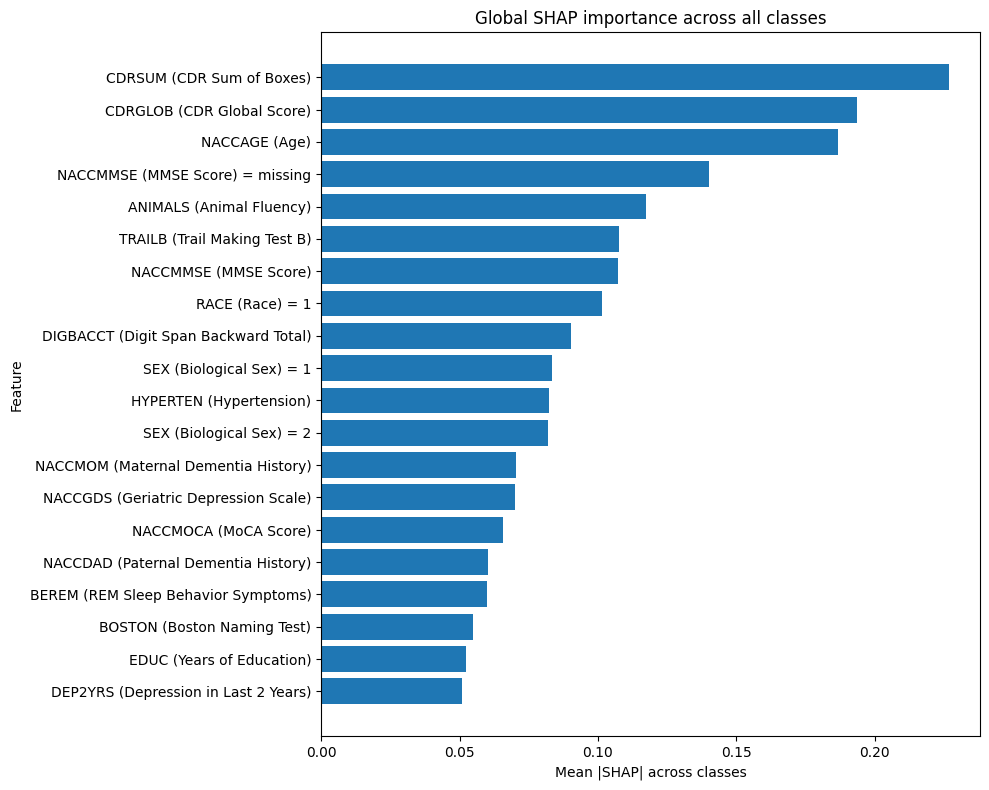

Saved: ../output/shap_outputs/figures/bar_global_shap_overall.png


,feature,mean_abs_shap,feature_label
19,num__CDRSUM,0.226690,CDRSUM (CDR Sum of Boxes)
18,num__CDRGLOB,0.193600,CDRGLOB (CDR Global Score)
49,num__NACCAGE,0.186844,NACCAGE (Age)
53,num__NACCMMSE_missing,0.139997,NACCMMSE (MMSE Score) = missing
10,num__ANIMALS,0.117453,ANIMALS (Animal Fluency)
70,num__TRAILB,0.107740,TRAILB (Trail Making Test B)
52,num__NACCMMSE,0.107391,NACCMMSE (MMSE Score)
2,cat__RACE_1,0.101319,RACE (Race) = 1
35,num__DIGBACCT,0.090115,DIGBACCT (Digit Span Backward Total)
8,cat__SEX_1,0.083541,SEX (Biological Sex) = 1


In [14]:
# Global SHAP importance across all classes

global_overall_df = (
    global_shap_df.groupby("feature", as_index=False)["mean_abs_shap"]
    .mean()
    .sort_values("mean_abs_shap", ascending=False)
)

global_overall_df["feature_label"] = global_overall_df["feature"].apply(readable_feature_name)

global_overall_df.to_csv(
    os.path.join(OUTPUT_DIR, "global_shap_importance_overall.csv"),
    index=False
)

tmp = global_overall_df.head(20).iloc[::-1]

plt.figure(figsize=(10, 8))
plt.barh(tmp["feature_label"], tmp["mean_abs_shap"])
plt.xlabel("Mean |SHAP| across classes")
plt.ylabel("Feature")
plt.title("Global SHAP importance across all classes")
plt.tight_layout()
save_current_fig("bar_global_shap_overall.png")
plt.show()
plt.close()

display(global_overall_df.head(20))

In [15]:
# Signed SHAP direction tables at transformed-feature level

signed_rows = []

for k, cls in enumerate(class_order):
    mean_shap = shap_exp.values[:, :, k].mean(axis=0)
    mean_abs_shap = np.abs(shap_exp.values[:, :, k]).mean(axis=0)

    tmp = pd.DataFrame({
        "class": cls,
        "feature_raw": feature_names_pre,
        "mean_shap": mean_shap,
        "mean_abs_shap": mean_abs_shap,
    }).sort_values("mean_abs_shap", ascending=False)

    signed_rows.append(tmp)

signed_shap_df = pd.concat(signed_rows, ignore_index=True)
signed_shap_df.to_csv(
    os.path.join(OUTPUT_DIR, "global_shap_signed_transformed.csv"),
    index=False
)

display(signed_shap_df.groupby("class").head(15))

,class,feature_raw,mean_shap,mean_abs_shap
0,AD,num__CDRGLOB,-1.306886e-02,0.237853
1,AD,num__CDRSUM,-1.564886e-02,0.188561
2,AD,num__NACCMMSE_missing,1.139125e-02,0.183969
3,AD,num__NACCMOCA,3.107099e-02,0.167212
4,AD,num__NACCMMSE,-1.538423e-02,0.157442
5,AD,cat__SEX_1,-3.201213e-03,0.078494
6,AD,cat__SEX_2,-3.119143e-03,0.076481
7,AD,num__NACCDAD,6.207184e-03,0.075495
8,AD,cat__RACE_1,-2.875809e-03,0.062765
9,AD,num__DIGBACCT,-1.457787e-02,0.054727


In [16]:
# Signed SHAP direction tables at collapsed/base-feature level

collapsed_signed_rows = []

tmp_signed = signed_shap_df.copy()
tmp_signed["feature_base"] = tmp_signed["feature_raw"].apply(collapse_feature_name)

collapsed_signed_df = (
    tmp_signed.groupby(["class", "feature_base"], as_index=False)
    .agg(
        mean_shap=("mean_shap", "sum"),
        mean_abs_shap=("mean_abs_shap", "sum")
    )
    .sort_values(["class", "mean_abs_shap"], ascending=[True, False])
)

collapsed_signed_df.to_csv(
    os.path.join(OUTPUT_DIR, "global_shap_signed_collapsed.csv"),
    index=False
)

display(collapsed_signed_df.groupby("class").head(20))

,class,feature_base,mean_shap,mean_abs_shap
8,AD,CDRGLOB,-0.013069,0.237853
9,AD,CDRSUM,-0.015649,0.188561
44,AD,NACCMMSE_missing,0.011391,0.183969
45,AD,NACCMOCA,0.031071,0.167212
43,AD,NACCMMSE,-0.015384,0.157442
...,...,...,...,...
245,Vascular,NACCMMSE_missing,-0.004558,0.073611
205,Vascular,BOSTON,-0.015864,0.067198
203,Vascular,BEREM,-0.016672,0.065019
218,Vascular,CVD,-0.045350,0.063127


## 7) Bar plots of top collapsed features per class

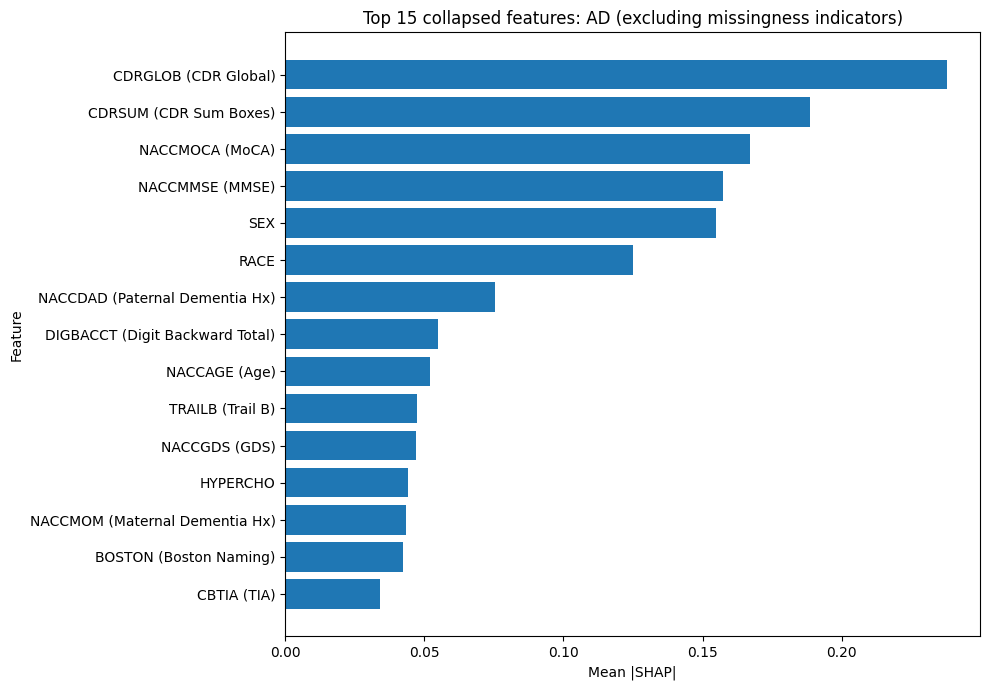

Saved: ../output/shap_outputs/figures/bar_top_15_AD_display_clean.png


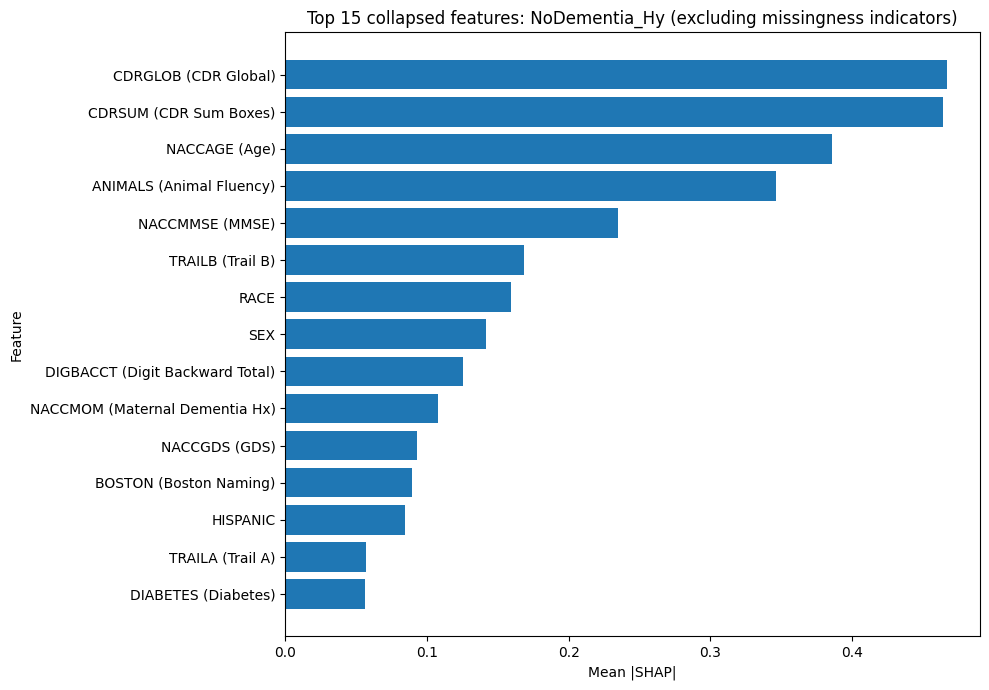

Saved: ../output/shap_outputs/figures/bar_top_15_NoDementia_Hy_display_clean.png


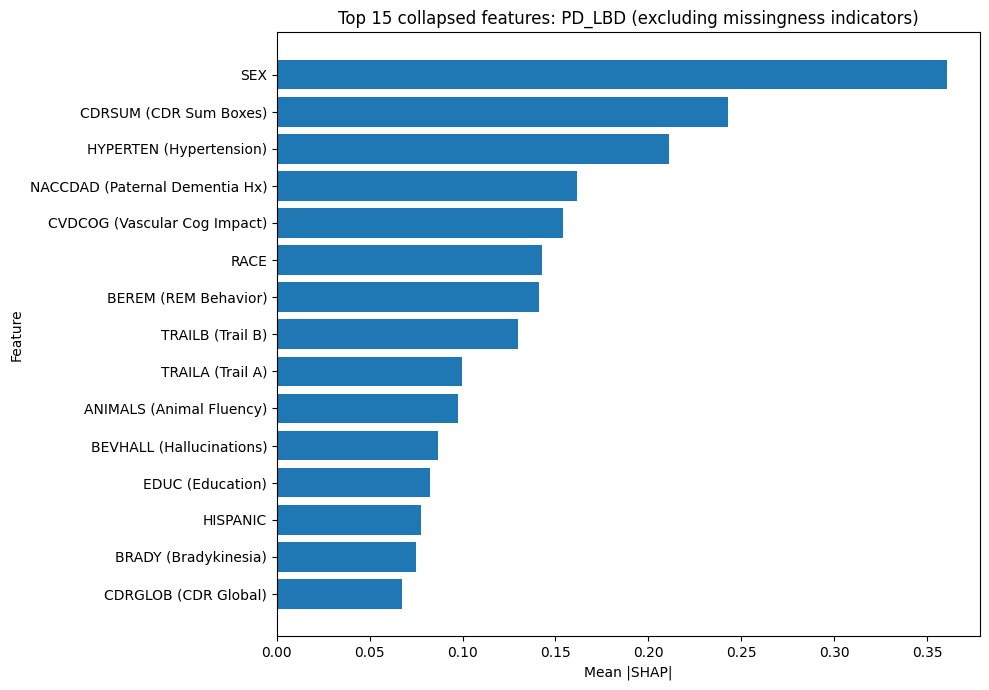

Saved: ../output/shap_outputs/figures/bar_top_15_PD_LBD_display_clean.png


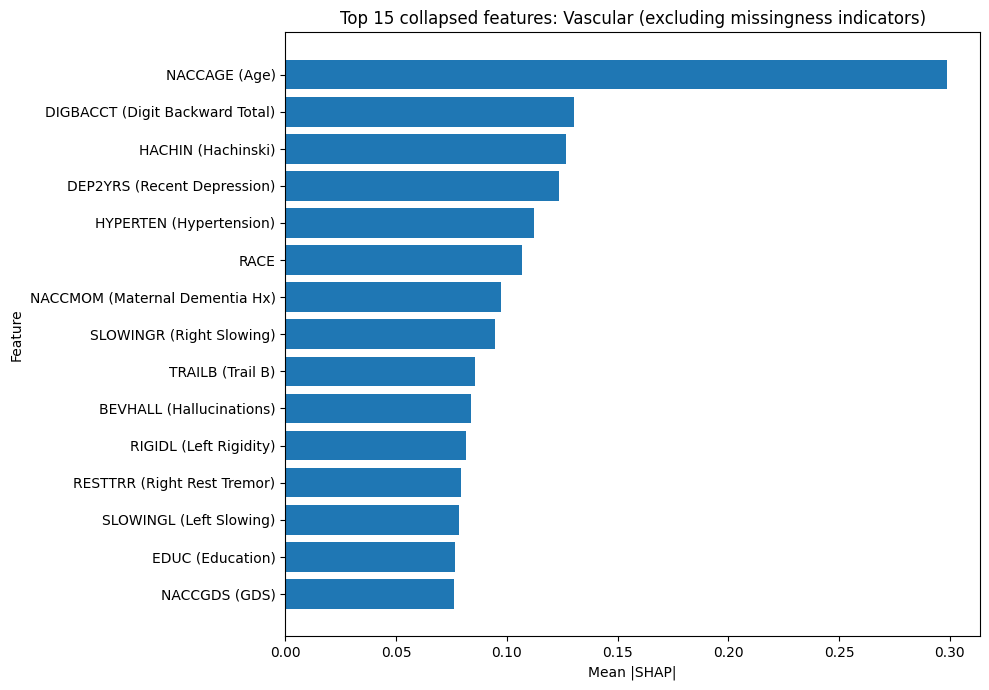

Saved: ../output/shap_outputs/figures/bar_top_15_Vascular_display_clean.png


In [17]:
TOP_N = 15

for cls in class_order:
    tmp = (
        collapsed_global_shap_display_df.loc[
            collapsed_global_shap_display_df["class"] == cls
        ]
        .sort_values("mean_abs_shap", ascending=False)
        .head(TOP_N)
        .iloc[::-1]
        .copy()
    )

    tmp["feature_label"] = tmp["feature_base"].apply(plot_feature_name)

    plt.figure(figsize=(10, 7))
    plt.barh(tmp["feature_label"], tmp["mean_abs_shap"])
    plt.xlabel("Mean |SHAP|")
    plt.ylabel("Feature")
    plt.title(f"Top {TOP_N} collapsed features: {cls} (excluding missingness indicators)")
    plt.tight_layout()
    save_current_fig(f"bar_top_{TOP_N}_{cls}_display_clean.png")
    plt.show()
    plt.close()

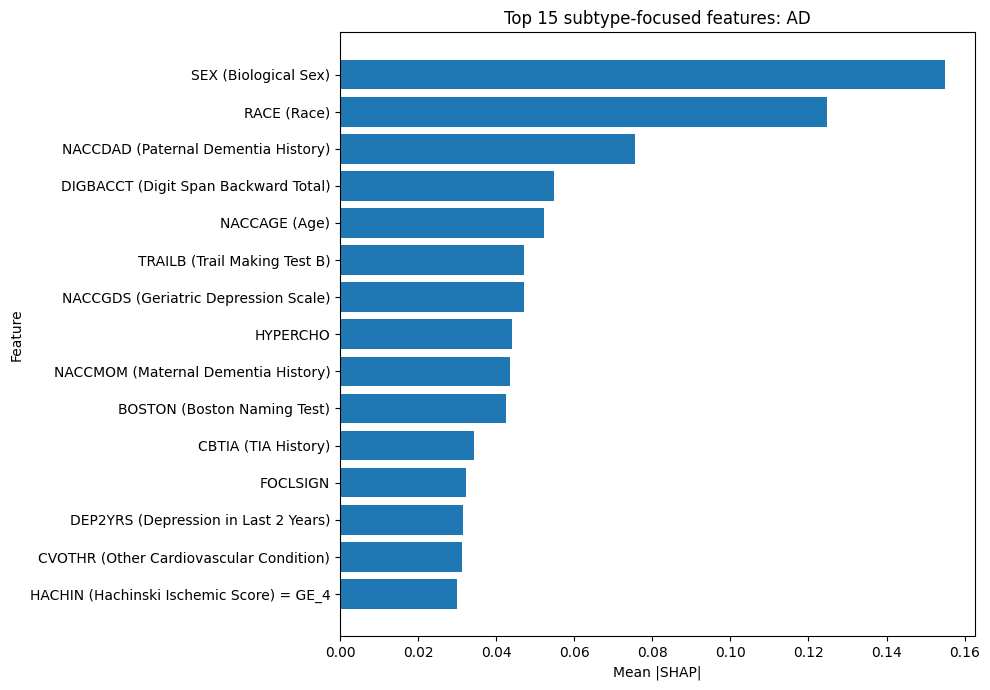

Saved: ../output/shap_outputs/figures/bar_top_15_AD_clinical.png


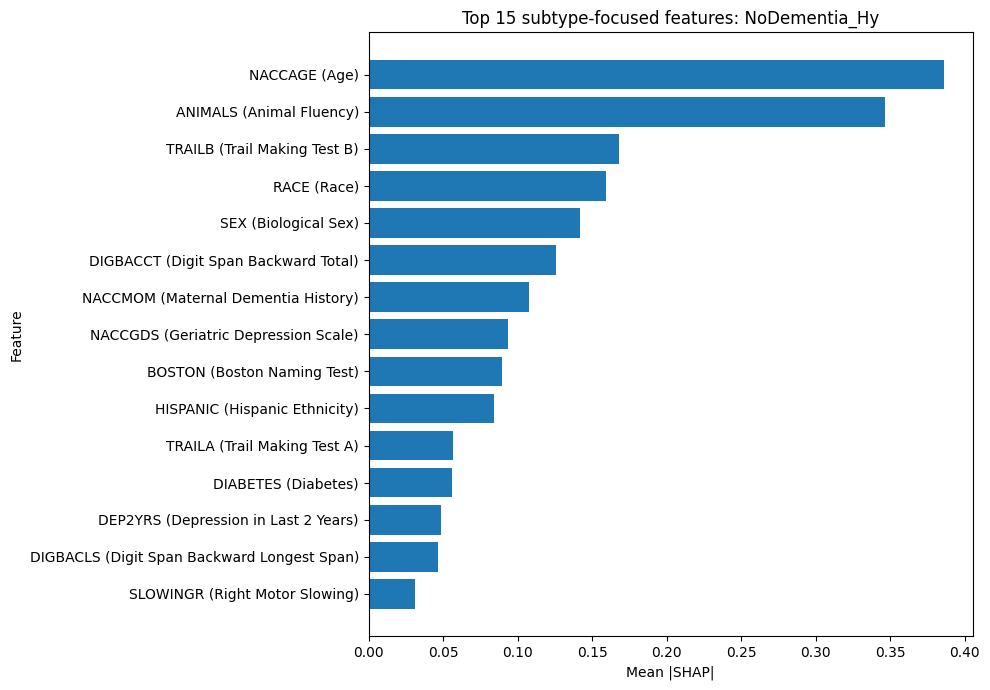

Saved: ../output/shap_outputs/figures/bar_top_15_NoDementia_Hy_clinical.png


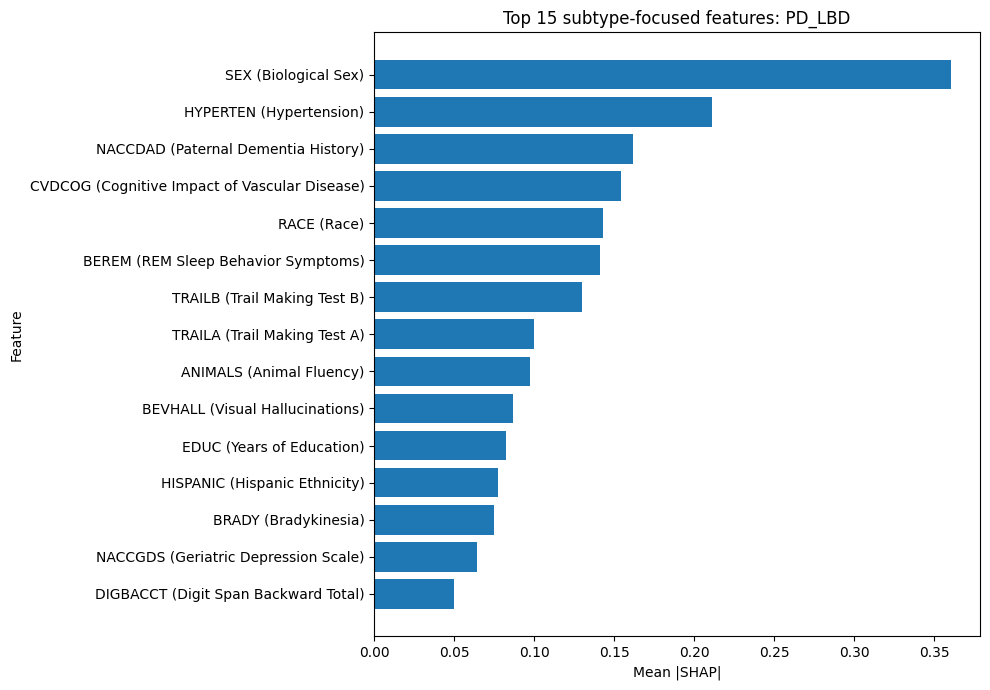

Saved: ../output/shap_outputs/figures/bar_top_15_PD_LBD_clinical.png


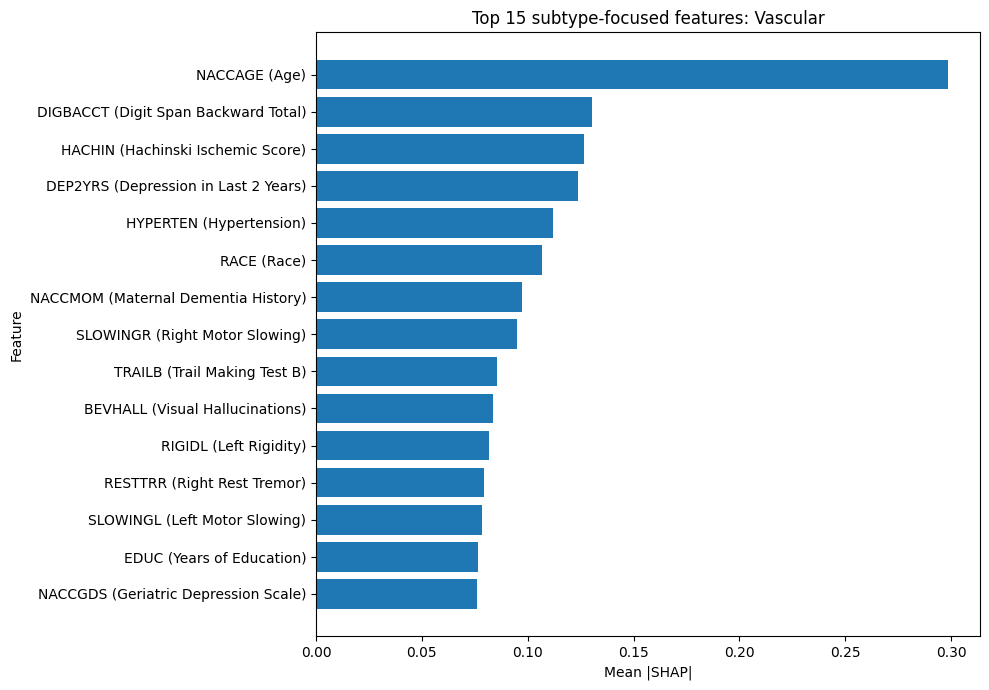

Saved: ../output/shap_outputs/figures/bar_top_15_Vascular_clinical.png


In [18]:
# Clinical-subtype display set:
# hiding missingness + broad severity variables from the display only

HIDE_FOR_CLINICAL_PLOTS = {
    "CDRGLOB",
    "CDRSUM",
    "NACCMMSE",
    "NACCMOCA",
}

def is_display_feature_clinical(feat: str) -> bool:
    feat_u = str(feat).upper()
    if is_missing_feature_name(feat_u):
        return False
    if feat_u in HIDE_FOR_CLINICAL_PLOTS:
        return False
    return True

collapsed_global_shap_clinical_df = collapsed_global_shap_df[
    collapsed_global_shap_df["feature_base"].apply(is_display_feature_clinical)
].copy()

collapsed_global_shap_clinical_df.to_csv(
    os.path.join(OUTPUT_DIR, "global_shap_importance_collapsed_clinical.csv"),
    index=False
)

for cls in class_order:
    tmp = (
        collapsed_global_shap_clinical_df.loc[
            collapsed_global_shap_clinical_df["class"] == cls
        ]
        .sort_values("mean_abs_shap", ascending=False)
        .head(TOP_N)
        .iloc[::-1]
        .copy()
    )

    tmp["feature_label"] = tmp["feature_base"].apply(readable_feature_name)

    plt.figure(figsize=(10, 7))
    plt.barh(tmp["feature_label"], tmp["mean_abs_shap"])
    plt.xlabel("Mean |SHAP|")
    plt.ylabel("Feature")
    plt.title(f"Top {TOP_N} subtype-focused features: {cls}")
    plt.tight_layout()
    save_current_fig(f"bar_top_{TOP_N}_{cls}_clinical.png")
    plt.show()
    plt.close()

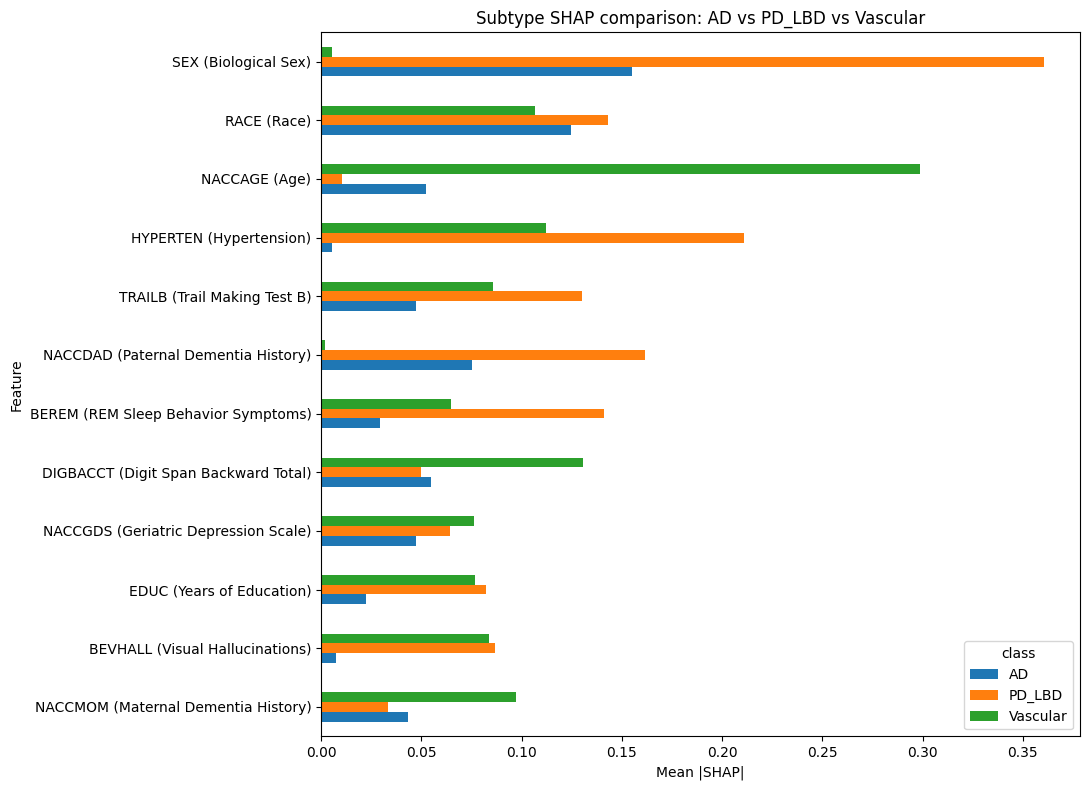

Saved: ../output/shap_outputs/figures/bar_subtype_shap_comparison.png


In [19]:
# Subtype SHAP comparison plot: AD vs PD_LBD vs Vascular

subtypes_to_compare = ["AD", "PD_LBD", "Vascular"]

compare_df = collapsed_global_shap_clinical_df[
    collapsed_global_shap_clinical_df["class"].isin(subtypes_to_compare)
].copy()

top_features_compare = (
    compare_df.groupby("feature_base", as_index=False)["mean_abs_shap"]
    .mean()
    .sort_values("mean_abs_shap", ascending=False)
    .head(12)["feature_base"]
    .tolist()
)

plot_df = compare_df[compare_df["feature_base"].isin(top_features_compare)].copy()
plot_df["feature_label"] = plot_df["feature_base"].apply(readable_feature_name)

pivot_df = plot_df.pivot(index="feature_label", columns="class", values="mean_abs_shap").fillna(0)

# sorting by average importance
pivot_df["avg"] = pivot_df.mean(axis=1)
pivot_df = pivot_df.sort_values("avg", ascending=True).drop(columns="avg")

ax = pivot_df.plot(kind="barh", figsize=(11, 8))
ax.set_xlabel("Mean |SHAP|")
ax.set_ylabel("Feature")
ax.set_title("Subtype SHAP comparison: AD vs PD_LBD vs Vascular")
plt.tight_layout()
save_current_fig("bar_subtype_shap_comparison.png")
plt.show()
plt.close()

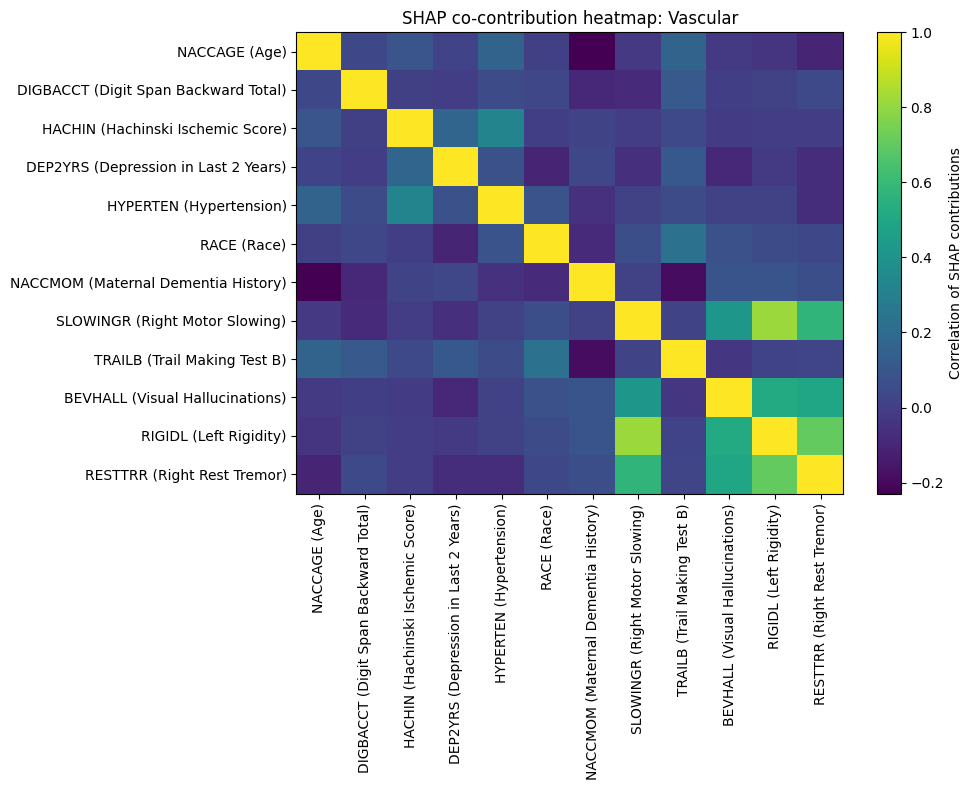

Saved: ../output/shap_outputs/figures/heatmap_shap_cocontribution_Vascular.png


In [20]:
# SHAP co-contribution heatmap 

target_cls = "Vascular"   # change to "AD" or "PD_LBD" if desired
k = list(class_order).index(target_cls)

top_feats = (
    collapsed_global_shap_clinical_df.loc[
        collapsed_global_shap_clinical_df["class"] == target_cls
    ]
    .sort_values("mean_abs_shap", ascending=False)
    .head(12)["feature_base"]
    .tolist()
)

feature_to_cols = {}
for j, f in enumerate(feature_names_pre):
    base = collapse_feature_name(f)
    feature_to_cols.setdefault(base, []).append(j)

heatmap_matrix = []
labels = []

for feat in top_feats:
    idxs = feature_to_cols.get(feat, [])
    if len(idxs) == 0:
        continue
    vals = shap_exp.values[:, idxs, k].sum(axis=1)
    heatmap_matrix.append(vals)
    labels.append(readable_feature_name(feat))

heatmap_df = pd.DataFrame(heatmap_matrix, index=labels).T
corr_df = heatmap_df.corr()

plt.figure(figsize=(10, 8))
plt.imshow(corr_df, aspect="auto")
plt.xticks(range(len(corr_df.columns)), corr_df.columns, rotation=90)
plt.yticks(range(len(corr_df.index)), corr_df.index)
plt.colorbar(label="Correlation of SHAP contributions")
plt.title(f"SHAP co-contribution heatmap: {target_cls}")
plt.tight_layout()
save_current_fig(f"heatmap_shap_cocontribution_{target_cls}.png")
plt.show()
plt.close()

## 8) Threshold-aware prediction table for the vascular override

In [21]:

proba_test = clf_best.predict_proba(X_test)


base_pred_test = np.array([class_order[np.argmax(p)] for p in proba_test])
final_pred_test = predict_with_vascular_threshold(proba_test, class_order, best_T)

vas_idx = list(class_order).index("Vascular")

threshold_df = pd.DataFrame({
    "NACCID": df4.loc[X_test.index, "NACCID"].values,
    "true_label": y_test.values,
    "base_pred": base_pred_test,
    "final_pred": final_pred_test,
    "prob_vascular": proba_test[:, vas_idx],
    "vascular_threshold": best_T,
    "vascular_margin": proba_test[:, vas_idx] - best_T
})

for j, cls in enumerate(class_order):
    threshold_df[f"prob_{cls}"] = proba_test[:, j]
    
threshold_csv = TABLE_DIR / "vascular_threshold_analysis_test.csv"
threshold_df.to_csv(threshold_csv, index=False)

vas_idx = list(class_order).index("Vascular")

threshold_df["vascular_prob"] = proba_test[:, vas_idx]
threshold_df["vascular_margin"] = threshold_df["vascular_prob"] - best_T
threshold_df["vascular_override_applied"] = (
    (threshold_df["final_pred"] == "Vascular") &
    (threshold_df["base_pred"] != "Vascular")
)

threshold_df["near_vascular_threshold"] = threshold_df["vascular_margin"].abs() <= 0.05

vascular_threshold_csv = TABLE_DIR / "vascular_threshold_analysis_detailed.csv"
threshold_df.to_csv(vascular_threshold_csv, index=False)

display(
    threshold_df.sort_values("vascular_margin", ascending=False).head(20)
)

print("Saved:", threshold_csv)
display(threshold_df.head(10))


,NACCID,true_label,base_pred,final_pred,prob_vascular,vascular_threshold,vascular_margin,prob_AD,prob_NoDementia_Hy,prob_PD_LBD,prob_Vascular,vascular_prob,vascular_override_applied,near_vascular_threshold
2399,NACC449214,AD,Vascular,Vascular,0.972233,0.36,0.612233,0.007045,0.020537,0.000185,0.972233,0.972233,False,False
203,NACC087117,Vascular,Vascular,Vascular,0.970879,0.36,0.610879,0.023829,0.005247,0.000044,0.970879,0.970879,False,False
1049,NACC344666,AD,Vascular,Vascular,0.956284,0.36,0.596284,0.038857,0.004112,0.000747,0.956284,0.956284,False,False
771,NACC070360,NoDementia_Hy,Vascular,Vascular,0.909958,0.36,0.549958,0.007943,0.077274,0.004824,0.909958,0.909958,False,False
1737,NACC846464,Vascular,Vascular,Vascular,0.886103,0.36,0.526103,0.074833,0.036139,0.002925,0.886103,0.886103,False,False
2091,NACC340799,AD,Vascular,Vascular,0.837005,0.36,0.477005,0.081377,0.081248,0.000371,0.837005,0.837005,False,False
1484,NACC822377,Vascular,Vascular,Vascular,0.813801,0.36,0.453801,0.141691,0.028462,0.016045,0.813801,0.813801,False,False
2267,NACC388114,Vascular,Vascular,Vascular,0.795935,0.36,0.435935,0.051650,0.151597,0.000818,0.795935,0.795935,False,False
1254,NACC861111,NoDementia_Hy,Vascular,Vascular,0.788459,0.36,0.428459,0.081052,0.120119,0.010370,0.788459,0.788459,False,False
748,NACC389961,Vascular,Vascular,Vascular,0.777781,0.36,0.417781,0.136613,0.018232,0.067375,0.777781,0.777781,False,False


Saved: ../output/shap_outputs/tables/vascular_threshold_analysis_test.csv


,NACCID,true_label,base_pred,final_pred,prob_vascular,vascular_threshold,vascular_margin,prob_AD,prob_NoDementia_Hy,prob_PD_LBD,prob_Vascular,vascular_prob,vascular_override_applied,near_vascular_threshold
0,NACC056862,NoDementia_Hy,NoDementia_Hy,NoDementia_Hy,0.003717,0.36,-0.356283,0.084686,0.909083,0.002514,0.003717,0.003717,False,False
1,NACC774813,NoDementia_Hy,NoDementia_Hy,NoDementia_Hy,0.001510,0.36,-0.358490,0.083031,0.911624,0.003834,0.001510,0.001510,False,False
2,NACC989206,NoDementia_Hy,NoDementia_Hy,NoDementia_Hy,0.002761,0.36,-0.357239,0.064886,0.930616,0.001737,0.002761,0.002761,False,False
3,NACC735141,AD,AD,AD,0.028955,0.36,-0.331045,0.810163,0.082353,0.078528,0.028955,0.028955,False,False
4,NACC252819,NoDementia_Hy,AD,AD,0.025498,0.36,-0.334502,0.609807,0.352915,0.011779,0.025498,0.025498,False,False
5,NACC205986,NoDementia_Hy,AD,AD,0.017977,0.36,-0.342023,0.509304,0.426286,0.046434,0.017977,0.017977,False,False
6,NACC148349,Vascular,AD,AD,0.051634,0.36,-0.308366,0.663701,0.128027,0.156638,0.051634,0.051634,False,False
7,NACC029156,NoDementia_Hy,NoDementia_Hy,NoDementia_Hy,0.006010,0.36,-0.353990,0.089209,0.887641,0.017139,0.006010,0.006010,False,False
8,NACC522352,NoDementia_Hy,NoDementia_Hy,NoDementia_Hy,0.001104,0.36,-0.358896,0.018450,0.979893,0.000553,0.001104,0.001104,False,False
9,NACC532829,NoDementia_Hy,NoDementia_Hy,NoDementia_Hy,0.001065,0.36,-0.358935,0.036845,0.961189,0.000901,0.001065,0.001065,False,False


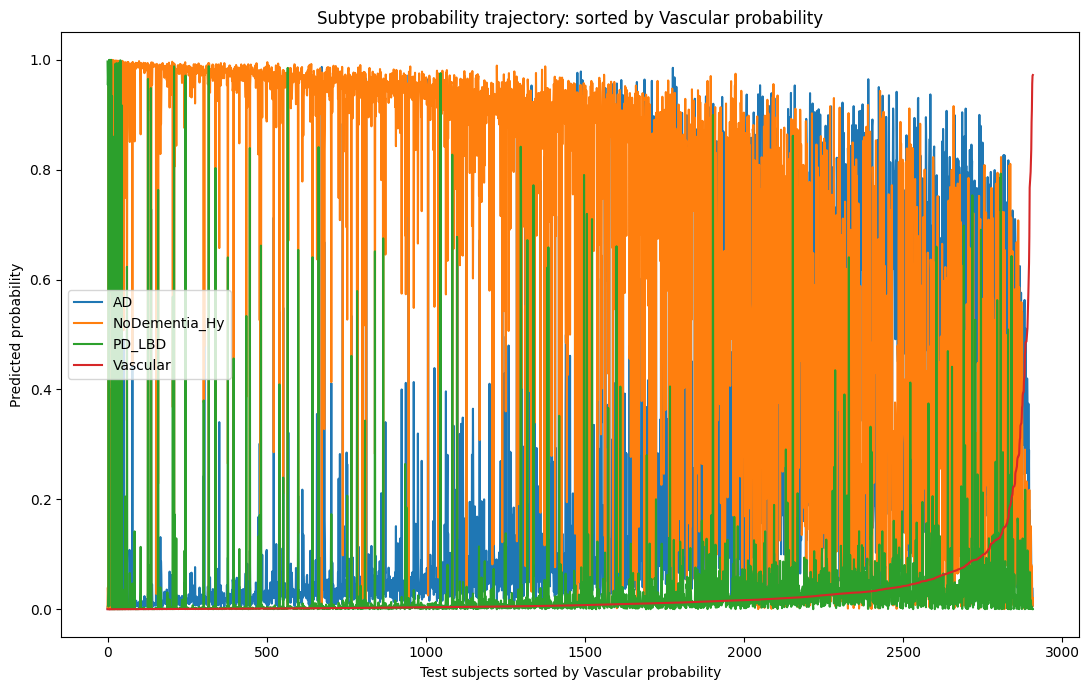

Saved: ../output/shap_outputs/figures/trajectory_probabilities_sorted_by_Vascular.png


In [22]:
# Subtype probability trajectory visualization

target_cls = "Vascular"  
target_col = f"prob_{target_cls}"

traj_df = threshold_df.copy().sort_values(target_col).reset_index(drop=True)

plt.figure(figsize=(11, 7))
for cls in class_order:
    plt.plot(traj_df[f"prob_{cls}"].values, label=cls)

plt.xlabel(f"Test subjects sorted by {target_cls} probability")
plt.ylabel("Predicted probability")
plt.title(f"Subtype probability trajectory: sorted by {target_cls} probability")
plt.legend()
plt.tight_layout()
save_current_fig(f"trajectory_probabilities_sorted_by_{target_cls}.png")
plt.show()
plt.close()

## 10) Local explanations for selected participants

below shows local waterfall plots for a few examples. 


In [23]:

example_indices = []

# threshold_df is aligned row-for-row with X_test
# X_explain / shap_exp only contain the first sample_size rows
threshold_explain_df = threshold_df.iloc[:sample_size].copy()

threshold_explain_df = threshold_explain_df.reset_index(drop=True)

# 1) Highest-confidence predicted AD
ad_mask = threshold_explain_df["final_pred"] == "AD"
if ad_mask.any():
    if "prob_AD" in threshold_explain_df.columns:
        ad_pos = threshold_explain_df.loc[ad_mask, "prob_AD"].idxmax()
    else:
        ad_pos = threshold_explain_df.index[ad_mask][0]
    example_indices.append(int(ad_pos))

# 2) Highest-confidence predicted PD_LBD
pd_mask = threshold_explain_df["final_pred"] == "PD_LBD"
if pd_mask.any():
    if "prob_PD_LBD" in threshold_explain_df.columns:
        pd_pos = threshold_explain_df.loc[pd_mask, "prob_PD_LBD"].idxmax()
    else:
        pd_pos = threshold_explain_df.index[pd_mask][0]
    example_indices.append(int(pd_pos))

# 3) Highest vascular margin case
vas_mask = threshold_explain_df["final_pred"] == "Vascular"
if vas_mask.any():
    vas_pos = threshold_explain_df.loc[vas_mask, "vascular_margin"].idxmax()
    example_indices.append(int(vas_pos))

# 4) Closest case to vascular threshold
near_pos = threshold_explain_df["vascular_margin"].abs().idxmin()
example_indices.append(int(near_pos))

example_indices = list(dict.fromkeys(example_indices))
print("Selected example positions in X_explain:", example_indices)

Selected example positions in X_explain: [195, 79, 203, 236]


In [24]:
print("sample_size =", sample_size)
print("example_indices =", example_indices)
print("max example index =", max(example_indices) if len(example_indices) else None)

sample_size = 300
example_indices = [195, 79, 203, 236]
max example index = 236


In [25]:
# Aligning all objects to the explained subset

X_test_explain = X_test.iloc[:sample_size].copy()
y_test_explain = y_test.iloc[:sample_size].reset_index(drop=True).copy()
threshold_explain_df = threshold_df.iloc[:sample_size].reset_index(drop=True).copy()

print("X_test_explain shape:", X_test_explain.shape)
print("y_test_explain shape:", y_test_explain.shape)
print("threshold_explain_df shape:", threshold_explain_df.shape)
print("X_explain shape:", X_explain.shape)
print("SHAP values shape:", shap_exp.values.shape)
print("Example indices:", example_indices)

X_test_explain shape: (300, 67)
y_test_explain shape: (300,)
threshold_explain_df shape: (300, 14)
X_explain shape: (300, 74)
SHAP values shape: (300, 74, 4)
Example indices: [195, 79, 203, 236]


Explain subset row: 195
Original X_test index: 37353
NACCID       : NACC973323
True label   : AD
Final pred   : AD
Probabilities: {np.str_('AD'): np.float64(0.9787), np.str_('NoDementia_Hy'): np.float64(0.0078), np.str_('PD_LBD'): np.float64(0.0062), np.str_('Vascular'): np.float64(0.0073)}
Vascular margin: -0.3527

--- Waterfall for class: AD ---


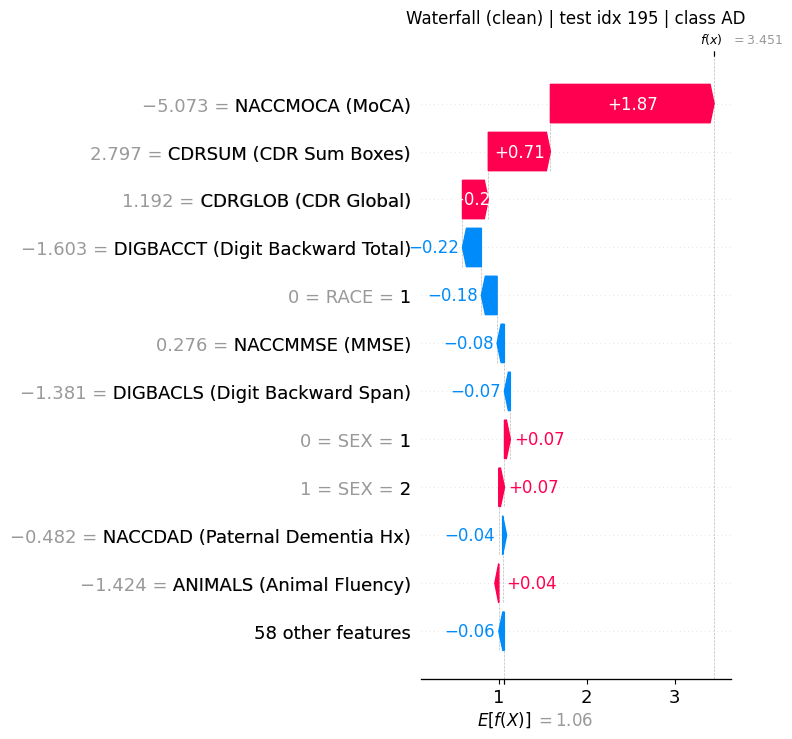

Saved: ../output/shap_outputs/figures/waterfall_testidx_195_AD_clean.png

--- Waterfall for class: NoDementia_Hy ---


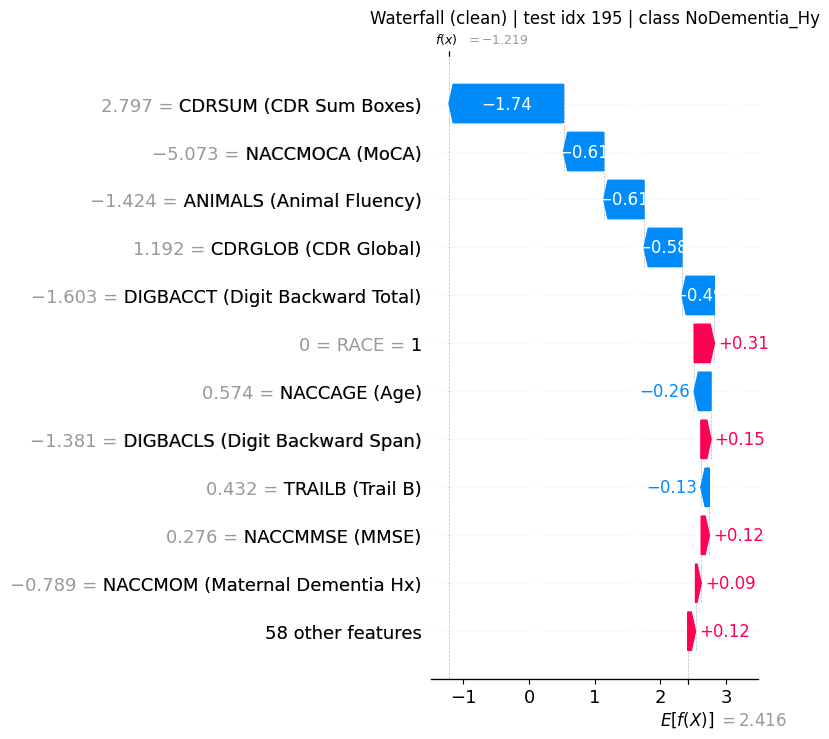

Saved: ../output/shap_outputs/figures/waterfall_testidx_195_NoDementia_Hy_clean.png

--- Waterfall for class: PD_LBD ---


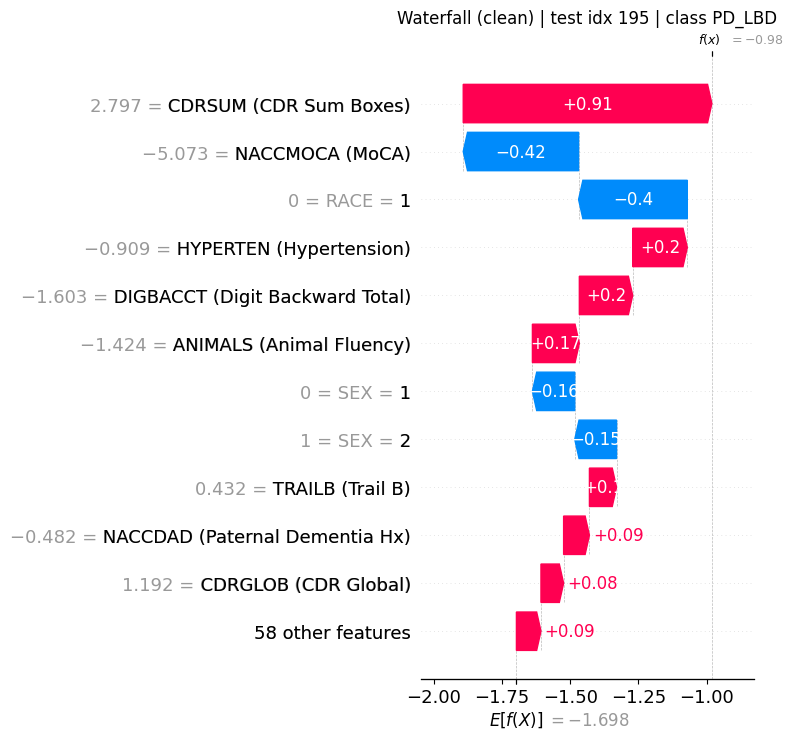

Saved: ../output/shap_outputs/figures/waterfall_testidx_195_PD_LBD_clean.png

--- Waterfall for class: Vascular ---


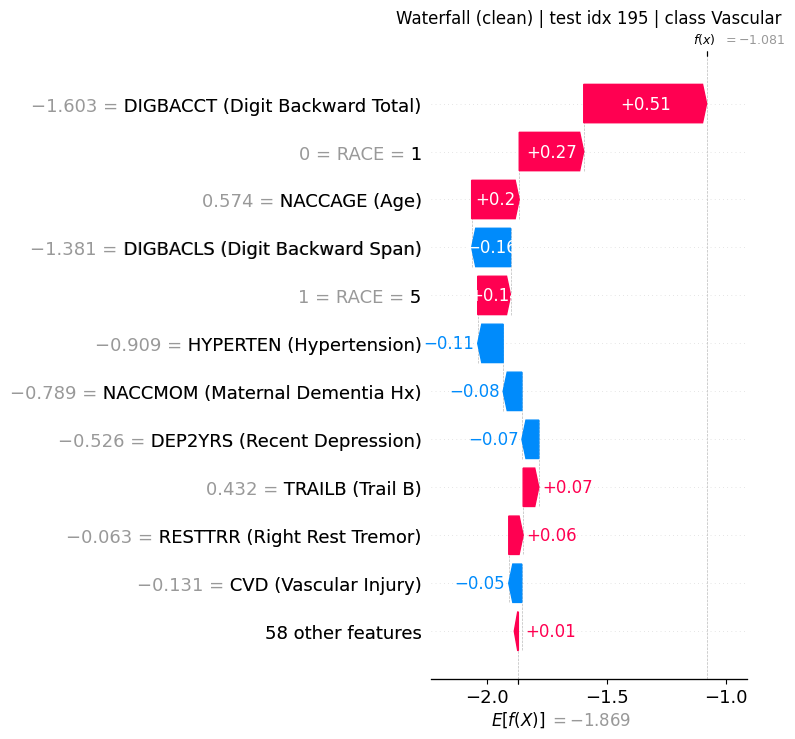

Saved: ../output/shap_outputs/figures/waterfall_testidx_195_Vascular_clean.png
Explain subset row: 79
Original X_test index: 31452
NACCID       : NACC817818
True label   : PD_LBD
Final pred   : PD_LBD
Probabilities: {np.str_('AD'): np.float64(0.0006), np.str_('NoDementia_Hy'): np.float64(0.0025), np.str_('PD_LBD'): np.float64(0.9969), np.str_('Vascular'): np.float64(0.0)}
Vascular margin: -0.3600

--- Waterfall for class: AD ---


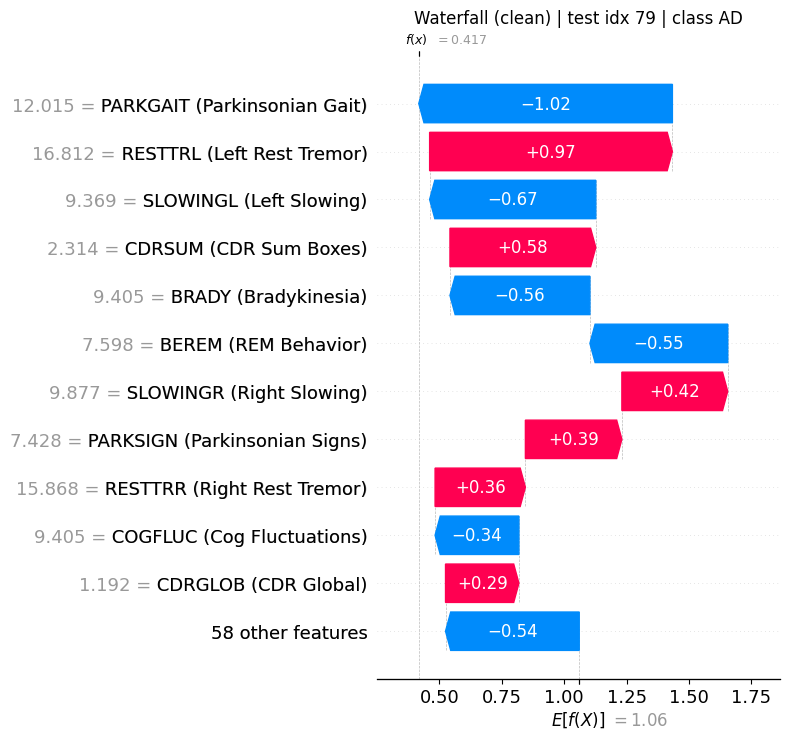

Saved: ../output/shap_outputs/figures/waterfall_testidx_79_AD_clean.png

--- Waterfall for class: NoDementia_Hy ---


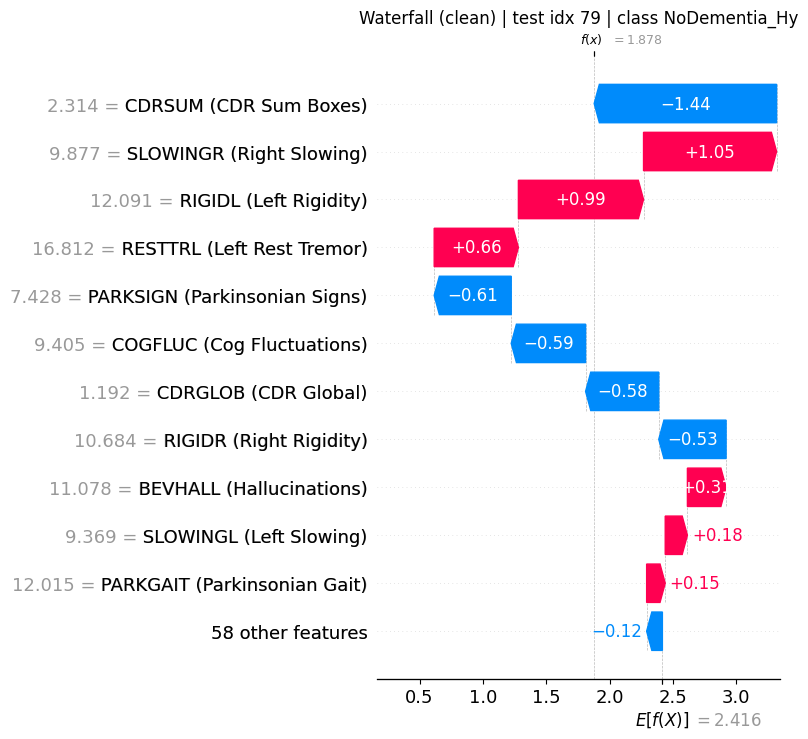

Saved: ../output/shap_outputs/figures/waterfall_testidx_79_NoDementia_Hy_clean.png

--- Waterfall for class: PD_LBD ---


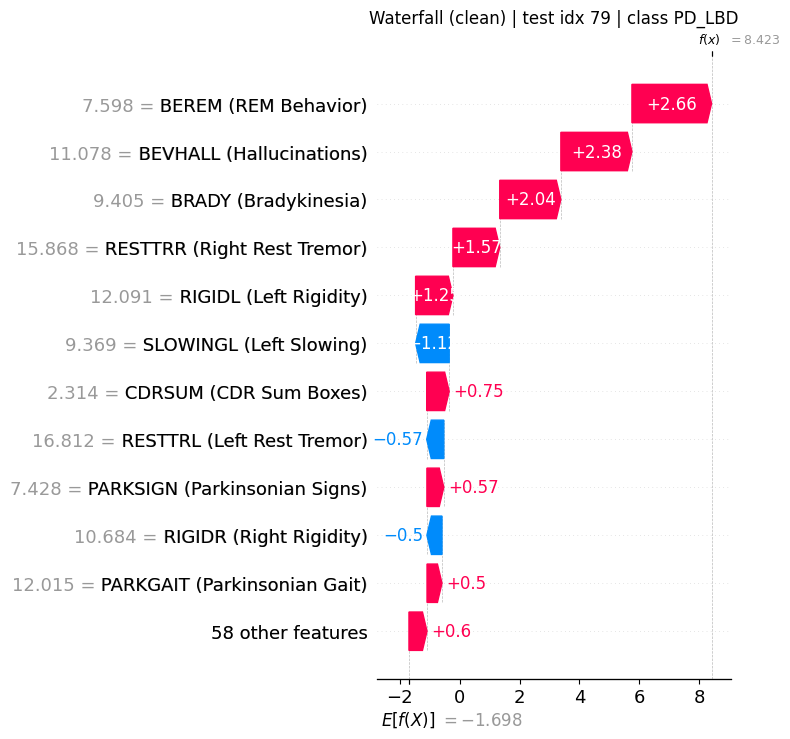

Saved: ../output/shap_outputs/figures/waterfall_testidx_79_PD_LBD_clean.png

--- Waterfall for class: Vascular ---


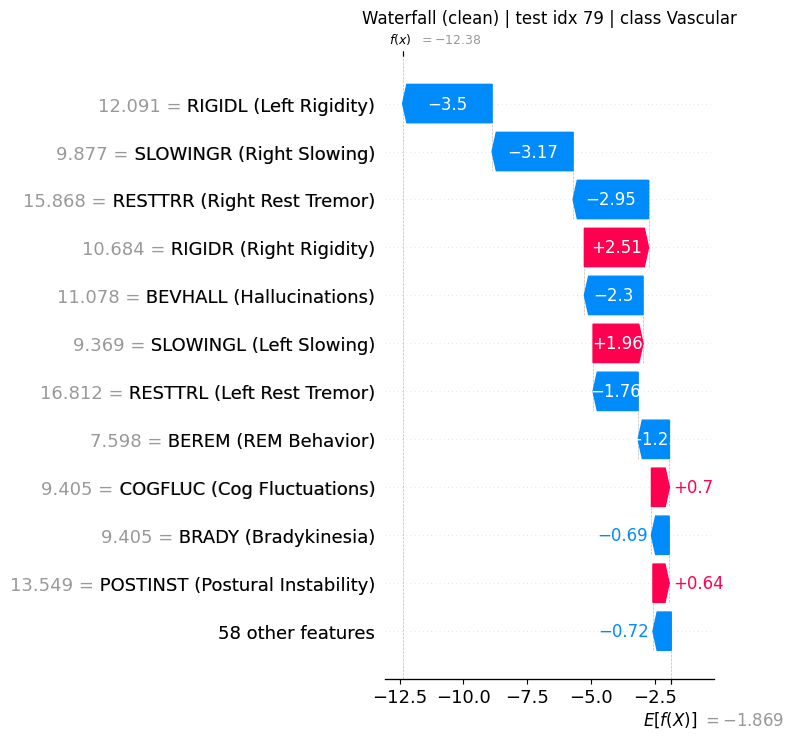

Saved: ../output/shap_outputs/figures/waterfall_testidx_79_Vascular_clean.png
Explain subset row: 203
Original X_test index: 3378
NACCID       : NACC087117
True label   : Vascular
Final pred   : Vascular
Probabilities: {np.str_('AD'): np.float64(0.0238), np.str_('NoDementia_Hy'): np.float64(0.0052), np.str_('PD_LBD'): np.float64(0.0), np.str_('Vascular'): np.float64(0.9709)}
Vascular margin: 0.6109

--- Waterfall for class: AD ---


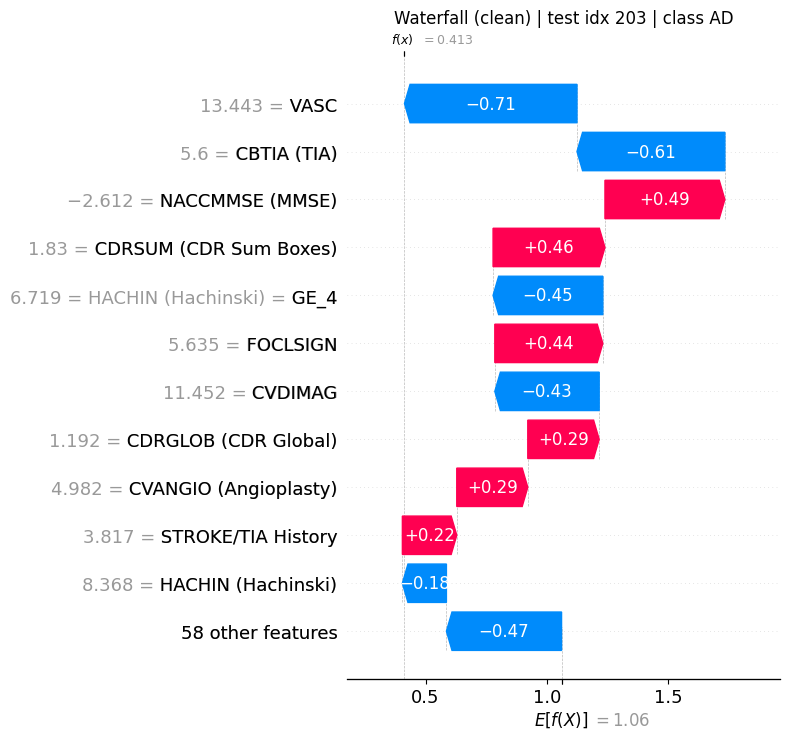

Saved: ../output/shap_outputs/figures/waterfall_testidx_203_AD_clean.png

--- Waterfall for class: NoDementia_Hy ---


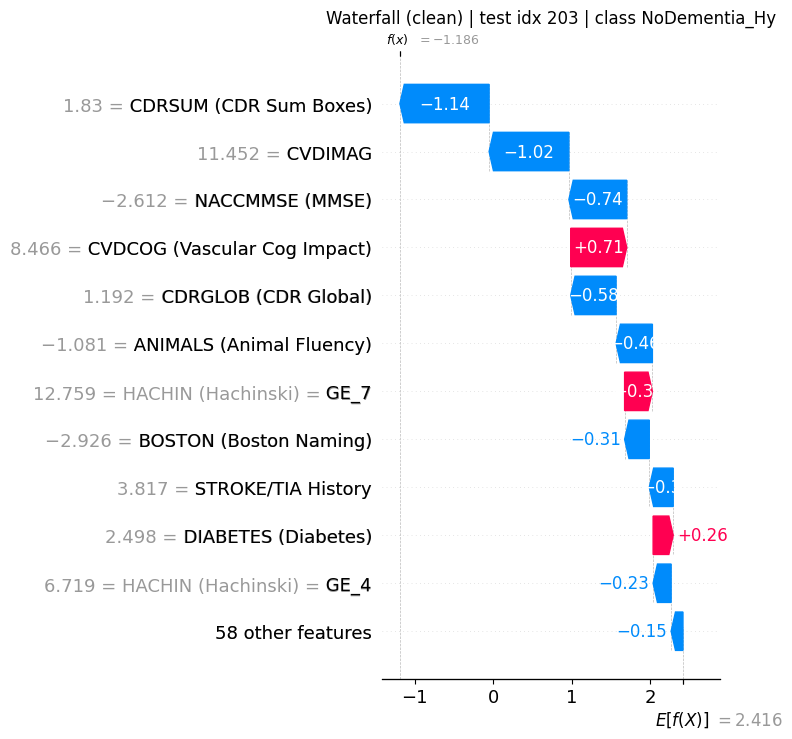

Saved: ../output/shap_outputs/figures/waterfall_testidx_203_NoDementia_Hy_clean.png

--- Waterfall for class: PD_LBD ---


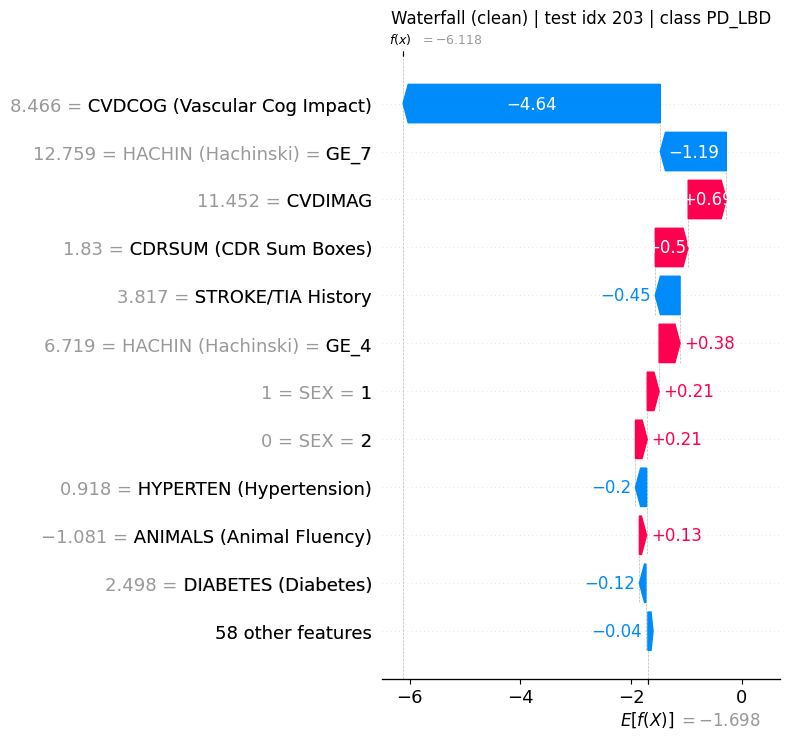

Saved: ../output/shap_outputs/figures/waterfall_testidx_203_PD_LBD_clean.png

--- Waterfall for class: Vascular ---


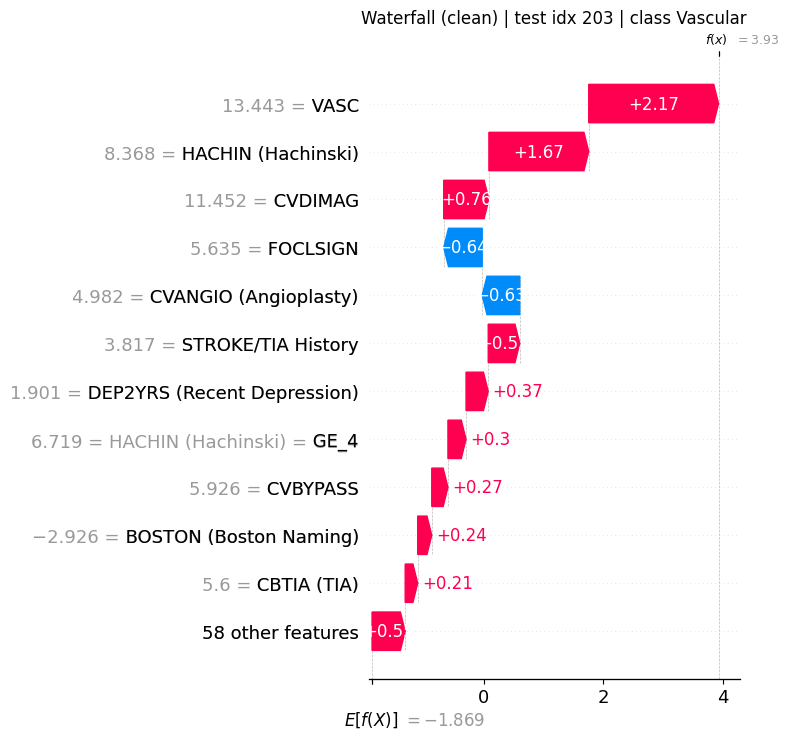

Saved: ../output/shap_outputs/figures/waterfall_testidx_203_Vascular_clean.png
Explain subset row: 236
Original X_test index: 37320
NACCID       : NACC972306
True label   : Vascular
Final pred   : Vascular
Probabilities: {np.str_('AD'): np.float64(0.2479), np.str_('NoDementia_Hy'): np.float64(0.2222), np.str_('PD_LBD'): np.float64(0.0339), np.str_('Vascular'): np.float64(0.4959)}
Vascular margin: 0.1359

--- Waterfall for class: AD ---


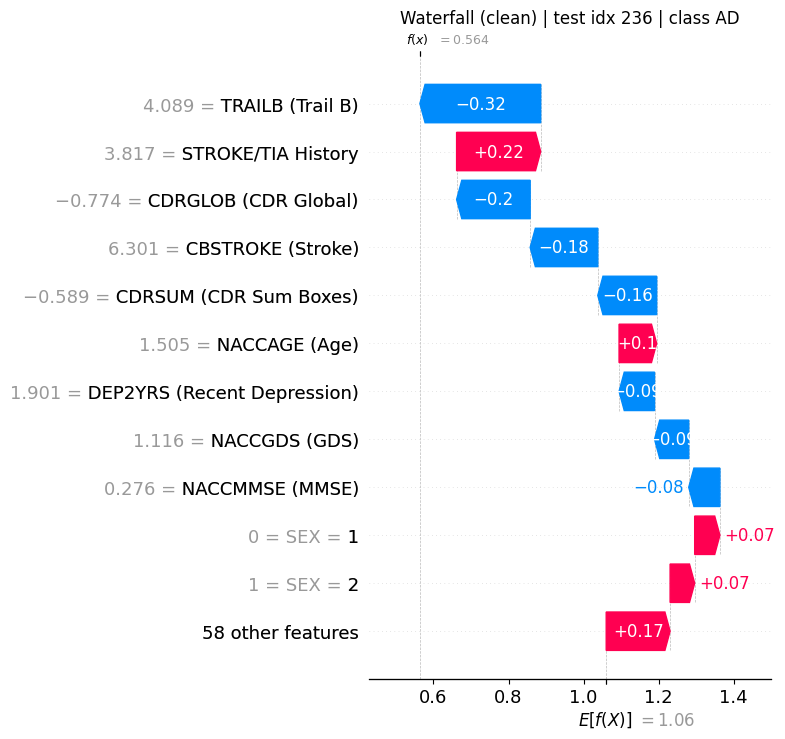

Saved: ../output/shap_outputs/figures/waterfall_testidx_236_AD_clean.png

--- Waterfall for class: NoDementia_Hy ---


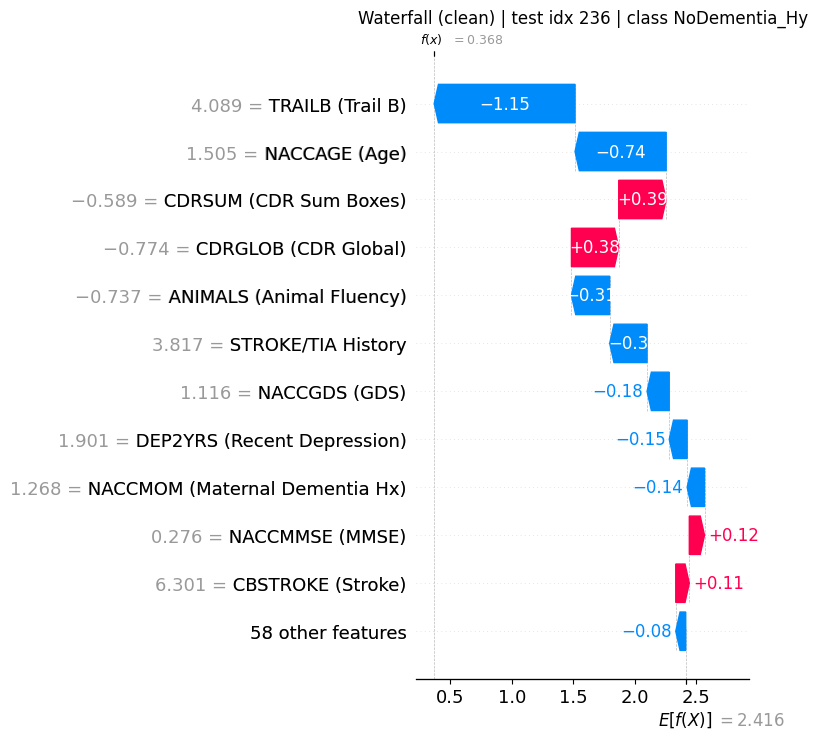

Saved: ../output/shap_outputs/figures/waterfall_testidx_236_NoDementia_Hy_clean.png

--- Waterfall for class: PD_LBD ---


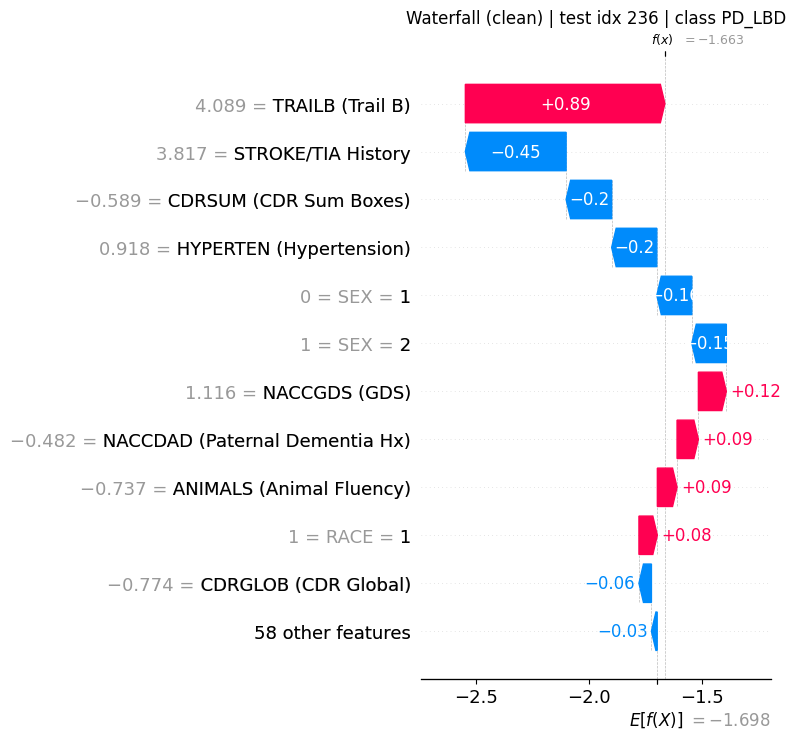

Saved: ../output/shap_outputs/figures/waterfall_testidx_236_PD_LBD_clean.png

--- Waterfall for class: Vascular ---


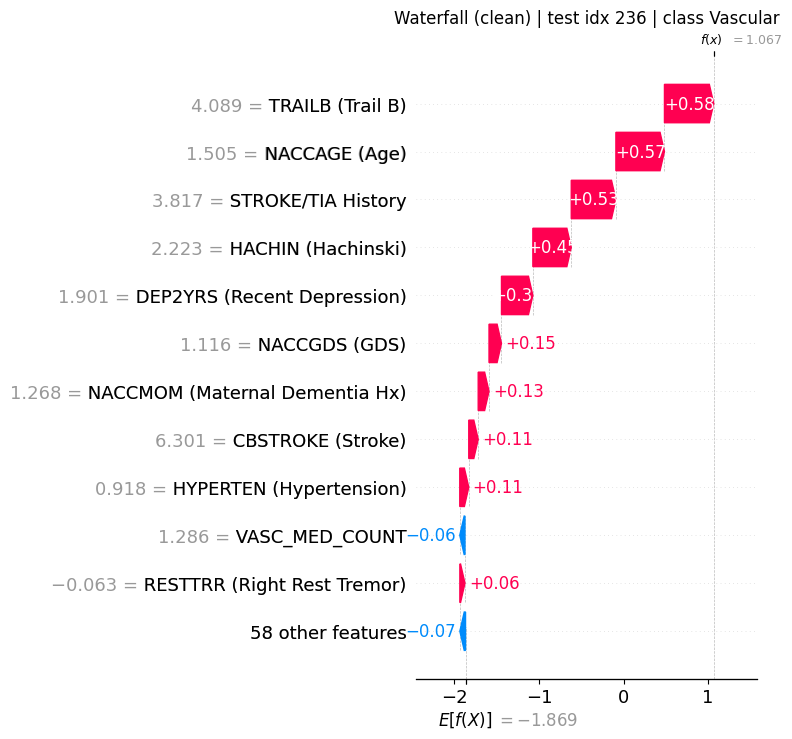

Saved: ../output/shap_outputs/figures/waterfall_testidx_236_Vascular_clean.png


In [26]:
for i in example_indices:
    if i < 0 or i >= sample_size:
        print(f"Skipping i={i} because it is outside explained subset 0..{sample_size-1}")
        continue

    original_idx = X_test_explain.index[i]

    if "NACCID" in df4.columns:
        naccid = df4.loc[original_idx, "NACCID"]
    else:
        naccid = original_idx

    true_label = y_test_explain.iloc[i]

    proba_i = clf_best.predict_proba(X_test_explain.iloc[[i]])[0]
    final_pred_i = predict_with_vascular_threshold(
        proba_i.reshape(1, -1), class_order, best_T
    )[0]

    print("=" * 80)
    print(f"Explain subset row: {i}")
    print(f"Original X_test index: {original_idx}")
    print(f"NACCID       : {naccid}")
    print(f"True label   : {true_label}")
    print(f"Final pred   : {final_pred_i}")
    print(f"Probabilities: {dict(zip(class_order, np.round(proba_i, 4)))}")
    print(f"Vascular margin: {proba_i[vas_idx] - best_T:.4f}")

    x_row_dense = row_to_dense(X_explain[i])

    for k, cls in enumerate(class_order):
        print(f"\n--- Waterfall for class: {cls} ---")

        if np.ndim(shap_exp.base_values) == 2:
            base_val = shap_exp.base_values[i, k]
        else:
            base_val = shap_exp.base_values[k]

        # full waterfall
        single_exp = shap.Explanation(
            values=shap_exp.values[i, :, k],
            base_values=base_val,
            data=x_row_dense,
            feature_names=[plot_feature_name(f) for f in feature_names_pre]
        )

        # plt.figure()
        # shap.plots.waterfall(single_exp, max_display=15, show=False)
        # save_current_fig(f"waterfall_testidx_{i}_{cls}.png")
        # plt.show()
        # plt.close()

        # clean waterfall (excluding _missing variables)
                # clean waterfall (excluding _missing variables)
        vals_full = shap_exp.values[i, :, k]

        keep_idx = [
            j for j, f in enumerate(feature_names_pre)
            if not str(f).upper().endswith("_MISSING")
        ]

        vals_clean = vals_full[keep_idx]
        data_clean = row_to_dense(X_explain[i])[keep_idx]
        feat_clean = [plot_feature_name(feature_names_pre[j]) for j in keep_idx]

        single_exp_clean = shap.Explanation(
            values=vals_clean,
            base_values=base_val,
            data=data_clean,
            feature_names=feat_clean
        )

        plt.figure(figsize=(13, 7))

        shap.plots.waterfall(single_exp_clean, max_display=12, show=False)

        ax = plt.gca()

        ax.tick_params(axis='x', labelsize=9)

        for text in ax.texts:
            text.set_fontsize(8)

        plt.gcf().subplots_adjust(left=0.45)

        plt.title(
            f"Waterfall (clean) | test idx {i} | class {cls}",
            fontsize=12
        )

        save_current_fig(f"waterfall_testidx_{i}_{cls}_clean.png")

        plt.show()
        plt.close()

In [27]:
# Exporting top positive / negative local SHAP contributors per selected subject

local_signed_rows = []

for i in example_indices:
    naccid = df.loc[X_test.index[i], "NACCID"] if "NACCID" in df.columns else X_test.index[i]

    for k, cls in enumerate(class_order):
        vals = shap_exp.values[i, :, k]

        pos_idx = np.argsort(vals)[::-1][:10]
        neg_idx = np.argsort(vals)[:10]

        for rank, j in enumerate(pos_idx, start=1):
            local_signed_rows.append({
                "NACCID": naccid,
                "test_index": i,
                "class": cls,
                "direction": "positive",
                "rank": rank,
                "feature": feature_names_pre[j],
                "shap_value": vals[j]
            })

        for rank, j in enumerate(neg_idx, start=1):
            local_signed_rows.append({
                "NACCID": naccid,
                "test_index": i,
                "class": cls,
                "direction": "negative",
                "rank": rank,
                "feature": feature_names_pre[j],
                "shap_value": vals[j]
            })

local_signed_df = pd.DataFrame(local_signed_rows)
local_signed_df.to_csv(
    os.path.join(OUTPUT_DIR, "local_top_positive_negative_shap.csv"),
    index=False
)

display(local_signed_df.head(20))

,NACCID,test_index,class,direction,rank,feature,shap_value
0,NACC973323,195,AD,positive,1,num__NACCMOCA,1.866123
1,NACC973323,195,AD,positive,2,num__CDRSUM,0.707905
2,NACC973323,195,AD,positive,3,num__NACCMMSE_missing,0.299020
3,NACC973323,195,AD,positive,4,num__CDRGLOB,0.294049
4,NACC973323,195,AD,positive,5,cat__SEX_1,0.067225
5,NACC973323,195,AD,positive,6,cat__SEX_2,0.065502
6,NACC973323,195,AD,positive,7,num__ANIMALS,0.043158
7,NACC973323,195,AD,positive,8,num__NACCAGE,0.034716
8,NACC973323,195,AD,positive,9,cat__RACE_2,0.031583
9,NACC973323,195,AD,positive,10,num__DEP2YRS,0.018007


## 10) Export top local SHAP drivers per subject

In [28]:

rows = []

for i in range(sample_size):
    naccid = df4.loc[X_test.index[i], "NACCID"]
    for k, cls in enumerate(class_order):
        vals = shap_exp.values[i, :, k]
        top_idx = np.argsort(np.abs(vals))[::-1][:10]
        for rank, j in enumerate(top_idx, start=1):
            rows.append({
                "NACCID": naccid,
                "class": cls,
                "rank": rank,
                "feature_raw": feature_names_pre[j],
                "feature_base": collapse_feature_name(feature_names_pre[j]),
                "shap_value": vals[j]
            })

local_top_shap_df = pd.DataFrame(rows)
local_csv = TABLE_DIR / "local_top10_shap_per_subject.csv"
local_top_shap_df.to_csv(local_csv, index=False)

print("Saved:", local_csv)
display(local_top_shap_df.head(20))


Saved: ../output/shap_outputs/tables/local_top10_shap_per_subject.csv


,NACCID,class,rank,feature_raw,feature_base,shap_value
0,NACC056862,AD,1,num__CDRGLOB,CDRGLOB,-0.196033
1,NACC056862,AD,2,num__NACCDAD,NACCDAD,0.188543
2,NACC056862,AD,3,num__CDRSUM,CDRSUM,-0.156900
3,NACC056862,AD,4,num__NACCMMSE_missing,NACCMMSE_missing,-0.128152
4,NACC056862,AD,5,num__NACCMMSE,NACCMMSE,-0.083075
5,NACC056862,AD,6,cat__SEX_1,SEX,0.067225
6,NACC056862,AD,7,cat__SEX_2,SEX,0.065502
7,NACC056862,AD,8,num__NACCMOM,NACCMOM,0.057159
8,NACC056862,AD,9,num__HYPERCHO,HYPERCHO,0.052031
9,NACC056862,AD,10,num__NACCGDS,NACCGDS,0.043876


## 12) Finding interesting vascular cases near the decision boundary



In [29]:

interesting_vascular = threshold_df.assign(
    abs_margin=lambda d: np.abs(d["vascular_margin"])
).sort_values(["final_pred", "abs_margin"], ascending=[True, True])

display(
    interesting_vascular[
        ["NACCID", "true_label", "base_pred", "final_pred", "prob_vascular", "vascular_threshold", "vascular_margin"]
    ].head(20)
)


,NACCID,true_label,base_pred,final_pred,prob_vascular,vascular_threshold,vascular_margin
1576,NACC776644,AD,AD,AD,0.337753,0.36,-0.022247
1401,NACC132410,NoDementia_Hy,AD,AD,0.335628,0.36,-0.024372
1680,NACC509898,NoDementia_Hy,AD,AD,0.311909,0.36,-0.048091
1866,NACC580504,NoDementia_Hy,AD,AD,0.308425,0.36,-0.051575
2785,NACC343175,AD,AD,AD,0.299750,0.36,-0.060250
2570,NACC789678,AD,AD,AD,0.280197,0.36,-0.079803
786,NACC333018,AD,AD,AD,0.280064,0.36,-0.079936
1245,NACC748379,Vascular,AD,AD,0.277114,0.36,-0.082886
2373,NACC603157,NoDementia_Hy,AD,AD,0.260015,0.36,-0.099985
617,NACC644290,AD,AD,AD,0.255117,0.36,-0.104883


In [30]:
# SHAP values here explain the multiclass logistic regression after preprocessing
# The final classifier also uses a vascular threshold override
# SHAP for the Vascular class
# vascular_margin = prob_vascular - threshold
# the collapsed feature tables are usually much easier to read than raw one-hot encoded features

In [31]:
print("INTERPRETATION GUIDE")
print("- Mean |SHAP| bar plots show which features matter most overall.")
print("- Beeswarm plots show both importance and direction.")
print("- Waterfall plots explain one participant at a time.")
print("- The 'clinical' plots hide broad severity variables to reveal subtype-specific signals.")
print("- Missingness indicators are kept in the model but hidden from display plots.")
print("- For vascular cases, also inspect vascular_margin and vascular_override_applied.")

INTERPRETATION GUIDE
- Mean |SHAP| bar plots show which features matter most overall.
- Beeswarm plots show both importance and direction.
- Waterfall plots explain one participant at a time.
- The 'clinical' plots hide broad severity variables to reveal subtype-specific signals.
- Missingness indicators are kept in the model but hidden from display plots.
- For vascular cases, also inspect vascular_margin and vascular_override_applied.
